# Análisis Quirúrgico y Estadístico — Actividad A5 (LLMs Comerciales vía API)

Evaluación exhaustiva sobre el conjunto **Test Gold (`data/labeled/test.jsonl`, $N = 2{.}798$)** bajo el diseño factorial completo $2 \times 2 \times 2$:
* **Modelos:** `gpt-4.1-mini` (OpenAI) vs. `gemini-3.8-flash` (Google Vertex AI, `thinking_level="LOW"`).
* **Representación de entrada:** Configuración **A** (Título + Abstract) vs. Configuración **B** (Sección retórica citante + Top-3 *chunks* recuperados).
* **Régimen de *prompting*:** **Zero-Shot** (`fs=0`) vs. **Few-Shot Estratificado con Vecindad Retórica (`fs=9`, `ARQ-09`)**.

Total auditado: **$8 \times 2{.}798 = 22{.}384$ predicciones reales** registradas en `models/llm_api_cache/*.jsonl`, `models/llm_api_*/metrics_summary.json` y `logs/llm_api_inference_*.log`.


## 1. Carga, Reconciliación e Integridad de Artefactos ($N = 2{.}798 \times 8 = 22{.}384$)

Se cargan exclusivamente las 8 corridas reales verificadas (con `config.json` y `metrics_summary.json`), se enlazan 1:1 con los registros de caché JSONL (`PredictionRecord`) y con la metadata completa del corpus de prueba (`data/labeled/test.jsonl`).


In [1]:
import json
import math
import re
import sys
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from scipy import stats
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support

BASE_DIR = Path('..') if Path('../data').exists() else Path('.')
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

from src.config.schema import CANONICAL_9_CLASSES, LABEL_TO_ID
from src.modeling.dataset import load_jsonl_instances
from src.modeling.evaluate import compute_a6_metrics, paired_significance_test

FIG_DIR = BASE_DIR / 'reports' / 'figures' / 'a5'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
    'axes.titlesize': 11.5,
    'axes.titleweight': 'bold',
})

VARIANTS = [
    ('gpt41_zs_a',   'GPT-4.1-mini · 0-Shot · A',   'llm_api_gpt41mini_zeroshot_config_a',   'gpt41mini_config_a.jsonl',     'gpt-4.1-mini',     0, 'A', ''),
    ('gpt41_zs_b',   'GPT-4.1-mini · 0-Shot · B',   'llm_api_gpt41mini_zeroshot_config_b',   'gpt41mini_config_b.jsonl',     'gpt-4.1-mini',     0, 'B', ''),
    ('gpt41_fs_a',   'GPT-4.1-mini · 9-Shot · A',   'llm_api_gpt41mini_fewshot_config_a',    'gpt41mini_config_a.jsonl',     'gpt-4.1-mini',     9, 'A', '::fs9'),
    ('gpt41_fs_b',   'GPT-4.1-mini · 9-Shot · B',   'llm_api_gpt41mini_fewshot_config_b',    'gpt41mini_config_b.jsonl',     'gpt-4.1-mini',     9, 'B', '::fs9'),
    ('gemini_zs_a',  'Gemini-3.8-Flash · 0-Shot · A', 'llm_api_gemini38flash_zeroshot_config_a', 'gemini38flash_config_a.jsonl', 'gemini-3.8-flash', 0, 'A', ''),
    ('gemini_zs_b',  'Gemini-3.8-Flash · 0-Shot · B', 'llm_api_gemini38flash_zeroshot_config_b', 'gemini38flash_config_b.jsonl', 'gemini-3.8-flash', 0, 'B', ''),
    ('gemini_fs_a',  'Gemini-3.8-Flash · 9-Shot · A', 'llm_api_gemini38flash_fewshot_config_a',  'gemini38flash_config_a.jsonl', 'gemini-3.8-flash', 9, 'A', '::fs9'),
    ('gemini_fs_b',  'Gemini-3.8-Flash · 9-Shot · B', 'llm_api_gemini38flash_fewshot_config_b',  'gemini38flash_config_b.jsonl', 'gemini-3.8-flash', 9, 'B', '::fs9'),
]

COLORS = {
    'gpt41_zs_a':  '#1f77b4',
    'gpt41_zs_b':  '#17becf',
    'gpt41_fs_a':  '#2ca02c',
    'gpt41_fs_b':  '#8c564b',
    'gemini_zs_a': '#ff7f0e',
    'gemini_zs_b': '#d62728',
    'gemini_fs_a': '#9467bd',
    'gemini_fs_b': '#e377c2',
}

test_path = BASE_DIR / 'data' / 'labeled' / 'test.jsonl'
test_raw = [json.loads(ln) for ln in test_path.read_text(encoding='utf-8').splitlines() if ln.strip()]
test_instances = load_jsonl_instances(test_path)
N_TEST = len(test_instances)
y_true = [inst.label for inst in test_instances]
y_true_idx = np.array([LABEL_TO_ID[lbl] for lbl in y_true], dtype=np.int64)

gold_df = pd.DataFrame([
    {
        'instance_id': r['instance_id'],
        'y_true': r['label'],
        'y_true_idx': LABEL_TO_ID[r['label']],
        'citing_section': (r.get('citing_paper') or {}).get('rhetorical_section'),
        'label_source': (r.get('annotation_metadata') or {}).get('label_source'),
        'prior_label_source': (r.get('annotation_metadata') or {}).get('prior_label_source'),
        'panel_agreement': (r.get('annotation_metadata') or {}).get('panel_agreement'),
        'panel_label': (r.get('annotation_metadata') or {}).get('panel_label'),
        'context_chars': len(r.get('citation_context') or ''),
        'context_words': len((r.get('citation_context') or '').split()),
    }
    for r in test_raw
])

print(f'Gold Test Split cargado: {test_path} | N = {N_TEST:,} instancias')
print(f"Cobertura citing_section no nula: {gold_df['citing_section'].notna().sum():,}/{N_TEST:,} ({gold_df['citing_section'].notna().mean()*100:.2f}%)")
print('Distribución label_source:', dict(gold_df['label_source'].value_counts(dropna=False)))
print('Distribución prior_label_source:', dict(gold_df['prior_label_source'].value_counts(dropna=False)))
print('Distribución panel_agreement:', dict(gold_df['panel_agreement'].round(4).value_counts(dropna=False)))


W1116 16:27:08.972000 42445 .venv/lib/python3.14/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1116 16:27:09.298000 42445 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:646] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1116 16:27:09.319000 42445 .venv/lib/python3.14/site-packages/torch/utils/_pytree.py:646] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Gold Test Split cargado: ../data/labeled/test.jsonl | N = 2,798 instancias
Cobertura citing_section no nula: 2,798/2,798 (100.00%)
Distribución label_source: {'human_review': np.int64(2798)}
Distribución prior_label_source: {'needs_review': np.int64(1120), 'llm_panel': np.int64(1115), 'human_gold': np.int64(563)}
Distribución panel_agreement: {0.6667: np.int64(1325), 1.0: np.int64(941), 0.3333: np.int64(532)}


In [2]:
# Carga de cachés JSONL, métricas A6/A7 y configuración exacta + verificación 1:1
caches_by_file = {}
for fname in sorted({v[3] for v in VARIANTS}):
    fpath = BASE_DIR / 'models' / 'llm_api_cache' / fname
    recs = {}
    with fpath.open('r', encoding='utf-8') as f:
        for line_no, ln in enumerate(f, 1):
            if not ln.strip():
                continue
            obj = json.loads(ln)
            rec = obj['record']
            rec['_cache_line'] = line_no
            rec['_cache_key'] = obj['cache_key']
            recs[obj['cache_key']] = rec
    caches_by_file[fname] = recs

runs = {}
rows_all = []
summary_rows = []

for vid, label, exp_dir_name, cache_fname, model_name, shots, cfg, suffix in VARIANTS:
    exp_dir = BASE_DIR / 'models' / exp_dir_name
    cfg_json = json.loads((exp_dir / 'config.json').read_text(encoding='utf-8'))
    ms = json.loads((exp_dir / 'metrics_summary.json').read_text(encoding='utf-8'))
    a6 = ms['test_metrics_a6']
    a7 = ms['operational_metrics_a7']
    preds_ms = ms['test_predictions']
    cache_map = caches_by_file[cache_fname]

    ordered_recs = []
    for idx, iid in enumerate(gold_df['instance_id']):
        ck = f'{iid}::{cfg}::generic::{model_name}{suffix}'
        rec = cache_map[ck]
        assert rec['predicted_label'] == preds_ms[idx], f'Mismatch en {vid} idx={idx}'
        ordered_recs.append(rec)

    a6_re = compute_a6_metrics(y_true, [r['predicted_label'] for r in ordered_recs])
    assert abs(a6_re.macro_f1_all_9 - a6['macro_f1_all_9']) < 1e-12

    probs_mat = np.array(
        [[float(r['probabilities'][c]) for c in CANONICAL_9_CLASSES] for r in ordered_recs],
        dtype=np.float64,
    )
    preds_lbl = [r['predicted_label'] for r in ordered_recs]
    preds_idx = np.array([LABEL_TO_ID[p] for p in preds_lbl], dtype=np.int64)

    runs[vid] = {
        'label': label,
        'exp_name': exp_dir_name,
        'model': model_name,
        'shots': shots,
        'cfg': cfg,
        'config_json': cfg_json,
        'a6': a6,
        'a7': a7,
        'records': ordered_recs,
        'y_pred': preds_lbl,
        'y_pred_idx': preds_idx,
        'probs': probs_mat,
    }

    n_valid_cache_hits = sum(1 for r in ordered_recs if r['cached_input_tokens'] > 0)
    n_thoughts = sum(1 for r in ordered_recs if r['thoughts_tokens'] > 0)
    n_invalid = sum(1 for r in ordered_recs if not r['is_valid_format'])
    lat_arr = np.array([r['latency_ms'] for r in ordered_recs], dtype=np.float64)

    summary_rows.append({
        'vid': vid,
        'Variante': label,
        'Modelo': model_name,
        'Shots': shots,
        'Config': cfg,
        'Macro-F1': a6['macro_f1_all_9'],
        'Weighted-F1': a6['weighted_f1'],
        'Accuracy': a6['micro_f1'],
        'Macro-Prec': a6['macro_precision'],
        'Macro-Rec': a6['macro_recall'],
        'Lat Media (ms)': a7['inference_latency_ms_per_instance'],
        'Lat p50 (ms)': float(np.median(lat_arr)),
        'Lat p95 (ms)': float(np.percentile(lat_arr, 95)),
        'Lat p99 (ms)': float(np.percentile(lat_arr, 99)),
        'Throughput (ej/s)': a7['throughput_instances_per_sec'],
        'Invalid (#)': n_invalid,
        'Invalid Rate': a7['invalid_format_rate'],
        'In Tokens': a7['total_input_tokens'],
        'Cached Tokens': a7['total_cached_input_tokens'],
        'Cache Token %': a7['cache_hit_rate'] * 100.0,
        'Cache Inst %': (n_valid_cache_hits / N_TEST) * 100.0,
        'Out Tokens': a7['total_output_tokens'],
        'Thoughts Tokens': a7['total_thoughts_tokens'],
        'Thoughts Inst (#)': n_thoughts,
        'Thoughts Inst %': (n_thoughts / N_TEST) * 100.0,
        'Costo Neto ($)': a7['estimated_api_cost_usd'],
        'Costo Bruto ($)': a7['gross_api_cost_usd'],
        'Ahorro Caché ($)': a7['gross_api_cost_usd'] - a7['estimated_api_cost_usd'],
    })

    for idx, r in enumerate(ordered_recs):
        rows_all.append({
            'vid': vid,
            'Variante': label,
            'Modelo': model_name,
            'Shots': shots,
            'Config': cfg,
            'instance_id': r['instance_id'],
            'test_idx': idx,
            'y_true': y_true[idx],
            'y_true_idx': int(y_true_idx[idx]),
            'y_pred': r['predicted_label'],
            'y_pred_idx': int(preds_idx[idx]),
            'is_correct': int(r['predicted_label'] == y_true[idx]),
            'confidence': float(r['confidence']),
            'max_prob': float(probs_mat[idx].max()),
            'prob_true': float(probs_mat[idx, y_true_idx[idx]]),
            'is_valid_format': bool(r['is_valid_format']),
            'input_tokens': int(r['input_tokens']),
            'cached_input_tokens': int(r['cached_input_tokens']),
            'uncached_input_tokens': int(r['input_tokens'] - r['cached_input_tokens']),
            'output_tokens': int(r['output_tokens']),
            'thoughts_tokens': int(r['thoughts_tokens']),
            'latency_ms': float(r['latency_ms']),
            'citing_section': gold_df.iloc[idx]['citing_section'],
            'label_source': gold_df.iloc[idx]['label_source'],
            'prior_label_source': gold_df.iloc[idx]['prior_label_source'],
            'panel_agreement': gold_df.iloc[idx]['panel_agreement'],
            'panel_label': gold_df.iloc[idx]['panel_label'],
            'context_chars': int(gold_df.iloc[idx]['context_chars']),
            '_cache_line': int(r['_cache_line']),
            '_cache_key': r['_cache_key'],
        })

df_summary = pd.DataFrame(summary_rows)
df_all = pd.DataFrame(rows_all)
print(f'Verificación 1:1 superada en las {len(runs)} variantes ({len(df_all):,} registros totales).')
print(f"Costo total Neto USD = ${df_summary['Costo Neto ($)'].sum():.4f} | Bruto USD = ${df_summary['Costo Bruto ($)'].sum():.4f} | Ahorro Caché = ${df_summary['Ahorro Caché ($)'].sum():.4f}")

# Auditoría de logs HTTP
log_stats = []
for lf in sorted((BASE_DIR / 'logs').glob('llm_api_inference_*.log')):
    if 'runner' in lf.name:
        continue
    txt = lf.read_text(encoding='utf-8', errors='replace')
    n_200 = len(re.findall(r'HTTP/1\.1 200 OK', txt))
    n_retry_gem = len(re.findall(r'Reintento Gemini', txt))
    n_retry_oai = len(re.findall(r'Retrying request', txt))
    log_stats.append({'Log': lf.name, 'HTTP_200': n_200, 'Reintentos_Gemini': n_retry_gem, 'Reintentos_OpenAI': n_retry_oai})
display(pd.DataFrame(log_stats))

cols_view = [
    'Variante', 'Macro-F1', 'Weighted-F1', 'Accuracy',
    'Lat Media (ms)', 'Lat p50 (ms)', 'Lat p95 (ms)', 'Lat p99 (ms)',
    'Invalid (#)', 'Cache Inst %', 'Cache Token %', 'Thoughts Inst (#)',
    'Costo Neto ($)', 'Costo Bruto ($)'
]
display(df_summary[cols_view].style.format({
    'Macro-F1': '{:.4f}', 'Weighted-F1': '{:.4f}', 'Accuracy': '{:.4f}',
    'Lat Media (ms)': '{:.1f}', 'Lat p50 (ms)': '{:.1f}', 'Lat p95 (ms)': '{:.1f}', 'Lat p99 (ms)': '{:.1f}',
    'Cache Inst %': '{:.2f}%', 'Cache Token %': '{:.2f}%',
    'Costo Neto ($)': '${:.4f}', 'Costo Bruto ($)': '${:.4f}',
}))


Verificación 1:1 superada en las 8 variantes (22,384 registros totales).
Costo total Neto USD = $44.4922 | Bruto USD = $55.1416 | Ahorro Caché = $10.6495


,Log,HTTP_200,Reintentos_Gemini,Reintentos_OpenAI
0,llm_api_inference_gemini38flash_config_a.log,5586,0,0
1,llm_api_inference_gemini38flash_config_b.log,5586,1,0
2,llm_api_inference_gpt41mini_config_a.log,5586,0,1
3,llm_api_inference_gpt41mini_config_b.log,5586,0,0


,Variante,Macro-F1,Weighted-F1,Accuracy,Lat Media (ms),Lat p50 (ms),Lat p95 (ms),Lat p99 (ms),Invalid (#),Cache Inst %,Cache Token %,Thoughts Inst (#),Costo Neto ($),Costo Bruto ($)
0,GPT-4.1-mini · 0-Shot · A,0.4493,0.5374,0.5021,941.7,915.9,1145.7,1445.8,0,1.25%,1.15%,0,$1.6311,$1.6428
1,GPT-4.1-mini · 0-Shot · B,0.4664,0.5642,0.5307,1121.0,1025.2,1502.3,2354.6,0,1.75%,1.63%,0,$1.8429,$1.8620
2,GPT-4.1-mini · 9-Shot · A,0.4146,0.4960,0.4643,1024.5,986.5,1306.2,1705.2,0,99.32%,83.06%,0,$2.3037,$5.6206
3,GPT-4.1-mini · 9-Shot · B,0.4242,0.5355,0.4964,1221.0,1045.6,1829.8,3406.0,0,99.43%,84.07%,0,$3.2482,$8.2852
4,Gemini-3.8-Flash · 0-Shot · A,0.5900,0.6900,0.6798,2829.6,2354.0,5269.3,10030.5,1,0.00%,0.00%,1214,$4.6320,$4.6320
5,Gemini-3.8-Flash · 0-Shot · B,0.5996,0.6933,0.6841,2810.4,2324.6,5118.8,11271.4,0,0.00%,0.00%,978,$4.9471,$4.9471
6,Gemini-3.8-Flash · 9-Shot · A,0.5974,0.6693,0.6565,2567.1,2292.4,4103.2,8010.3,1,11.29%,4.33%,4,$11.0328,$11.4325
7,Gemini-3.8-Flash · 9-Shot · B,0.5943,0.6652,0.6523,3369.7,2481.1,7612.4,19366.4,0,22.80%,13.39%,7,$14.8544,$16.7194


## 2. Diagnóstico Forense de las 2 Instancias Fallidas (`is_valid_format == False`)

Conforme a la decisión operativa aprobada, **se preservan intactos los archivos `metrics_summary.json` originales** (cero reinferencia, costo adicional `$0.00`). Se documenta aquí la trazabilidad completa de ambas instancias, su firma estructural de tokens de salida, la evidencia en logs HTTP, sus predicciones en las otras 7 corridas y su impacto real en métricas.


In [3]:
failed = df_all[~df_all['is_valid_format']].copy()
print(f'Total de registros con is_valid_format == False en los 22,384 llamados: {len(failed)}')

forensic_rows = []
for _, row in failed.iterrows():
    iid = row['instance_id']
    g_match = [r for r in test_raw if r['instance_id'] == iid][0]
    other_runs = df_all[(df_all['instance_id'] == iid) & (df_all['vid'] != row['vid'])][
        ['Variante', 'y_pred', 'confidence', 'output_tokens', 'latency_ms']
    ]
    print(f"\n--- FALLO: {iid} | {row['Variante']} | cache_key={row['_cache_key']} | línea_cache={row['_cache_line']} | test_idx={row['test_idx']} ---")
    print(f"Gold='{row['y_true']}' | Sección='{row['citing_section']}' | label_source={row['label_source']} (prior={row['prior_label_source']}) | panel_agreement={row['panel_agreement']}")
    print(f"Telemetría: input={row['input_tokens']}, cached={row['cached_input_tokens']}, output={row['output_tokens']}, thoughts={row['thoughts_tokens']}, latency_ms={row['latency_ms']:.2f}")
    print(f"Fallback aplicado en código: predicted_label='{row['y_pred']}', confidence={row['confidence']:.6f} (1/9)")
    print('Contexto citante:', g_match['citation_context'])
    display(other_runs.reset_index(drop=True))

    # Impacto contrafactual exacto si el registro fallido hubiera predicho y_true vs su predicción modal Gemini
    vid = row['vid']
    y_pred_cur = runs[vid]['y_pred'][:]
    y_pred_corr = y_pred_cur[:]
    y_pred_corr[row['test_idx']] = row['y_true']
    f1_cur = runs[vid]['a6']['macro_f1_all_9']
    acc_cur = runs[vid]['a6']['micro_f1']
    f1_cf = f1_score(y_true, y_pred_corr, labels=list(CANONICAL_9_CLASSES), average='macro', zero_division=0)
    acc_cf = accuracy_score(y_true, y_pred_corr)
    forensic_rows.append({
        'instance_id': iid,
        'Variante': row['Variante'],
        'cache_key': row['_cache_key'],
        'Línea Caché': row['_cache_line'],
        'Gold': row['y_true'],
        'Fallback': row['y_pred'],
        'Out Tokens': row['output_tokens'],
        'Latencia (ms)': row['latency_ms'],
        'Macro-F1 Observado': f1_cur,
        'Macro-F1 Si Acertada': f1_cf,
        'Δ Macro-F1 Potencial': f1_cf - f1_cur,
        'Δ Accuracy Potencial': acc_cf - acc_cur,
    })

display(pd.DataFrame(forensic_rows).style.format({
    'Latencia (ms)': '{:.2f}',
    'Macro-F1 Observado': '{:.6f}',
    'Macro-F1 Si Acertada': '{:.6f}',
    'Δ Macro-F1 Potencial': '{:+.6f}',
    'Δ Accuracy Potencial': '{:+.6f}',
}))

# Tabla resumen de distribución de output_tokens y detección de singletons anómalos
out_stats = []
for vid, rinfo in runs.items():
    sub = df_all[df_all['vid'] == vid]
    vc = dict(sorted(Counter(sub['output_tokens']).items()))
    inv_tokens = sorted(sub[~sub['is_valid_format']]['output_tokens'].tolist())
    val_tokens = sub[sub['is_valid_format']]['output_tokens']
    out_stats.append({
        'Variante': rinfo['label'],
        'Min Válido': int(val_tokens.min()),
        'Mediana Válida': float(val_tokens.median()),
        'Max Válido': int(val_tokens.max()),
        'Out Tokens en Inválidos': inv_tokens if inv_tokens else '—',
        'Top Modas': dict(Counter(sub['output_tokens']).most_common(4)),
    })
display(pd.DataFrame(out_stats))


Total de registros con is_valid_format == False en los 22,384 llamados: 2

--- FALLO: inst_17318 | Gemini-3.8-Flash · 0-Shot · A | cache_key=inst_17318::A::generic::gemini-3.8-flash | línea_cache=2795 | test_idx=2789 ---
Gold='Further Reading' | Sección='Parallel Implementation' | label_source=human_review (prior=needs_review) | panel_agreement=0.6666666666666666
Telemetría: input=1450, cached=0, output=125, thoughts=0, latency_ms=5477.04
Fallback aplicado en código: predicted_label='Background', confidence=0.111111 (1/9)
Contexto citante: I.e. one processor contains the same segments of $\mathbf {W}$ and $\sigma$ , which are then assembled consecutively in the solution vector. With this, the parallelization of the spatial operator does not have to be changed, see <cite>N. Krais, A. Beck, T. Bolemann, H. Frank, D. Flad, G. Gassner, F. Hindenlang, M. Hoffmann, T. Kuhn, M. Sonntag, et al., FLEXI: A high order discontinuous Galerkin framework for hyperbolic–parabolic conservation laws, Co

,Variante,y_pred,confidence,output_tokens,latency_ms
0,GPT-4.1-mini · 0-Shot · A,Background,0.95,66,1416.982042
1,GPT-4.1-mini · 0-Shot · B,Background,0.85,66,997.473084
2,GPT-4.1-mini · 9-Shot · A,Application,0.85,66,989.648041
3,GPT-4.1-mini · 9-Shot · B,Application,0.75,66,925.994667
4,Gemini-3.8-Flash · 0-Shot · B,Further Reading,0.80,120,2370.850125
5,Gemini-3.8-Flash · 9-Shot · A,Further Reading,0.75,75,2349.353875
6,Gemini-3.8-Flash · 9-Shot · B,Further Reading,0.78,123,2761.689583



--- FALLO: inst_17446 | Gemini-3.8-Flash · 9-Shot · A | cache_key=inst_17446::A::generic::gemini-3.8-flash::fs9 | línea_cache=5035 | test_idx=2236 ---
Gold='Further Reading' | Sección='Contributions of this paper' | label_source=human_review (prior=needs_review) | panel_agreement=0.6666666666666666
Telemetría: input=4840, cached=0, output=77, thoughts=0, latency_ms=12904.01
Fallback aplicado en código: predicted_label='Background', confidence=0.111111 (1/9)
Contexto citante: We provide experiments supporting this hypothesis for various target functions and architectures such as MLPs and the Transformers [OTHERCIT] in Section REF and Appendix . These rely on mini-batch stochastic gradient descent or Adam <cite>Diederik P Kingma and Jimmy Ba, 2014</cite> (see Section REF for more details). We establish formally this hypothesis for GD and linear regression models in Section REF , and conduct experiments to support it on multi-layer neural networks of large depths and small initialization

,Variante,y_pred,confidence,output_tokens,latency_ms
0,GPT-4.1-mini · 0-Shot · A,Application,1.00,66,895.160875
1,GPT-4.1-mini · 0-Shot · B,Application,1.00,66,954.580208
2,GPT-4.1-mini · 9-Shot · A,Application,0.85,66,1037.776750
3,GPT-4.1-mini · 9-Shot · B,Originator,0.83,67,892.337125
4,Gemini-3.8-Flash · 0-Shot · A,Application,0.90,120,1883.890500
5,Gemini-3.8-Flash · 0-Shot · B,Application,0.85,118,4916.200750
6,Gemini-3.8-Flash · 9-Shot · B,Application,0.85,122,2556.878625


,instance_id,Variante,cache_key,Línea Caché,Gold,Fallback,Out Tokens,Latencia (ms),Macro-F1 Observado,Macro-F1 Si Acertada,Δ Macro-F1 Potencial,Δ Accuracy Potencial
0,inst_17318,Gemini-3.8-Flash · 0-Shot · A,inst_17318::A::generic::gemini-3.8-flash,2795,Further Reading,Background,125,5477.04,0.589959,0.590257,+0.000298,+0.000357
1,inst_17446,Gemini-3.8-Flash · 9-Shot · A,inst_17446::A::generic::gemini-3.8-flash::fs9,5035,Further Reading,Background,77,12904.01,0.597412,0.597703,+0.000291,+0.000357


,Variante,Min Válido,Mediana Válida,Max Válido,Out Tokens en Inválidos,Top Modas
0,GPT-4.1-mini · 0-Shot · A,66,66.0,67,—,"{66: 2506, 67: 292}"
1,GPT-4.1-mini · 0-Shot · B,66,66.0,67,—,"{66: 2501, 67: 297}"
2,GPT-4.1-mini · 9-Shot · A,66,66.0,67,—,"{66: 2375, 67: 423}"
3,GPT-4.1-mini · 9-Shot · B,66,66.0,67,—,"{66: 2416, 67: 382}"
4,Gemini-3.8-Flash · 0-Shot · A,67,120.0,124,[125],"{122: 518, 123: 513, 118: 387, 119: 292}"
5,Gemini-3.8-Flash · 0-Shot · B,68,120.0,124,—,"{122: 520, 123: 466, 118: 462, 119: 304}"
6,Gemini-3.8-Flash · 9-Shot · A,71,122.0,124,[77],"{123: 1165, 122: 655, 75: 285, 74: 211}"
7,Gemini-3.8-Flash · 9-Shot · B,71,123.0,124,—,"{123: 1229, 122: 826, 121: 242, 124: 182}"


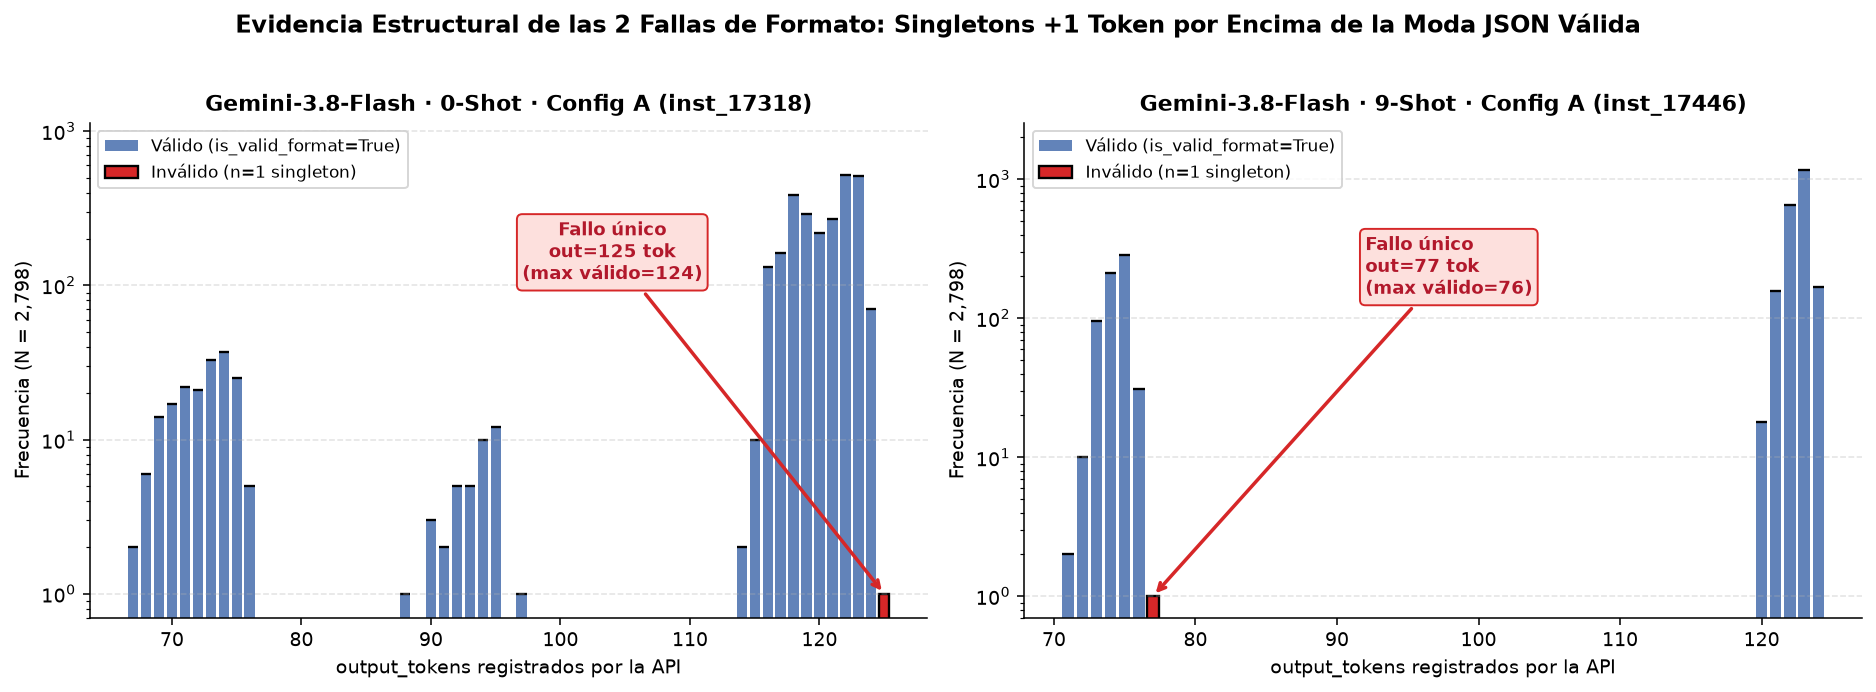

In [4]:
# Figura 1: Distribución de output_tokens y evidencia estructural de los 2 fallos de formato
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel A: Gemini Config A Zero-Shot vs Few-Shot (donde ocurren ambos fallos)
for ax, (vid, title_txt) in zip(
    axes,
    [
        ('gemini_zs_a', 'Gemini-3.8-Flash · 0-Shot · Config A (inst_17318)'),
        ('gemini_fs_a', 'Gemini-3.8-Flash · 9-Shot · Config A (inst_17446)'),
    ],
):
    sub = df_all[df_all['vid'] == vid]
    vc = sub.groupby(['output_tokens', 'is_valid_format']).size().unstack(fill_value=0)
    x_vals = vc.index.to_numpy()
    valid_cnt = vc[True].to_numpy() if True in vc.columns else np.zeros_like(x_vals)
    inv_cnt = vc[False].to_numpy() if False in vc.columns else np.zeros_like(x_vals)

    ax.bar(x_vals, valid_cnt, color='#4c72b0', alpha=0.88, label='Válido (is_valid_format=True)')
    if inv_cnt.sum() > 0:
        # Altura visible auxiliar en eje secundario o anotación sobre la barra real (1)
        ax.bar(x_vals, inv_cnt, bottom=valid_cnt, color='#d62728', edgecolor='black', linewidth=1.2,
               label='Inválido (n=1 singleton)')
        bad_x = x_vals[inv_cnt > 0][0]
        xt = 92 if bad_x < 90 else 104
        yt = 150 if bad_x < 90 else 110
        ax.annotate(
            f'Fallo único\nout={bad_x} tok\n(max válido={bad_x-1})',
            xy=(bad_x, 1),
            xytext=(xt, yt),
            ha='center' if bad_x >= 90 else 'left',
            arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.8),
            fontsize=9.2, fontweight='bold', color='#b2182b',
            bbox=dict(boxstyle='round,pad=0.3', fc='#fde0dd', ec='#d62728'),
        )
    ax.set_title(title_txt)
    ax.set_xlabel('output_tokens registrados por la API')
    ax.set_ylabel('Frecuencia (N = 2,798)')
    ax.set_yscale('log')
    ax.set_ylim(0.7, max(valid_cnt) * 2.2)
    ax.grid(axis='y', linestyle='--', alpha=0.35)
    ax.legend(loc='upper left', frameon=True, fontsize=8.5)

fig.suptitle('Evidencia Estructural de las 2 Fallas de Formato: Singletons +1 Token por Encima de la Moda JSON Válida',
             fontsize=12.5, fontweight='bold', y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig01_output_tokens_y_fallos_formato.png', bbox_inches='tight')
plt.show()


## 3. Eje 1A: Desempeño Predictivo Global, por Clase Canónica y por Sección Retórica

Se compara el rendimiento técnico sobre las 9 clases (`Macro-F1`, `Weighted-F1`, `Accuracy`), la vulnerabilidad en las clases de la tríada metodológica (`Improvement`, `Evidence`, `Basis`, `Comparison`) frente a categorías altamente lexicalizadas (`Further Reading`), el impacto de la sección citante y los pares críticos de confusión.


,Clase,Soporte,GPT-4.1-mini · 0-Shot · A,GPT-4.1-mini · 0-Shot · B,GPT-4.1-mini · 9-Shot · A,GPT-4.1-mini · 9-Shot · B,Gemini-3.8-Flash · 0-Shot · A,Gemini-3.8-Flash · 0-Shot · B,Gemini-3.8-Flash · 9-Shot · A,Gemini-3.8-Flash · 9-Shot · B
0,Background,1200,0.5050,0.5561,0.4590,0.5551,0.6921,0.6951,0.6472,0.6368
1,Gap,73,0.2222,0.2727,0.1682,0.1651,0.4162,0.4457,0.4319,0.4600
2,Basis,90,0.2333,0.2759,0.2042,0.2019,0.5660,0.5776,0.5338,0.5503
3,Comparison,298,0.6346,0.6255,0.5855,0.5679,0.6685,0.6567,0.6195,0.6222
4,Application,637,0.6488,0.6598,0.5833,0.5844,0.7753,0.7748,0.7690,0.7731
5,Improvement,68,0.3514,0.3567,0.2905,0.3268,0.4348,0.4561,0.5503,0.5263
6,Evidence,100,0.2876,0.3084,0.3042,0.3277,0.3874,0.3775,0.3608,0.3506
7,Originator,105,0.4767,0.4481,0.3925,0.3401,0.4392,0.4715,0.5243,0.4855
8,Further Reading,227,0.6838,0.6947,0.7441,0.7487,0.9301,0.9409,0.9399,0.9440


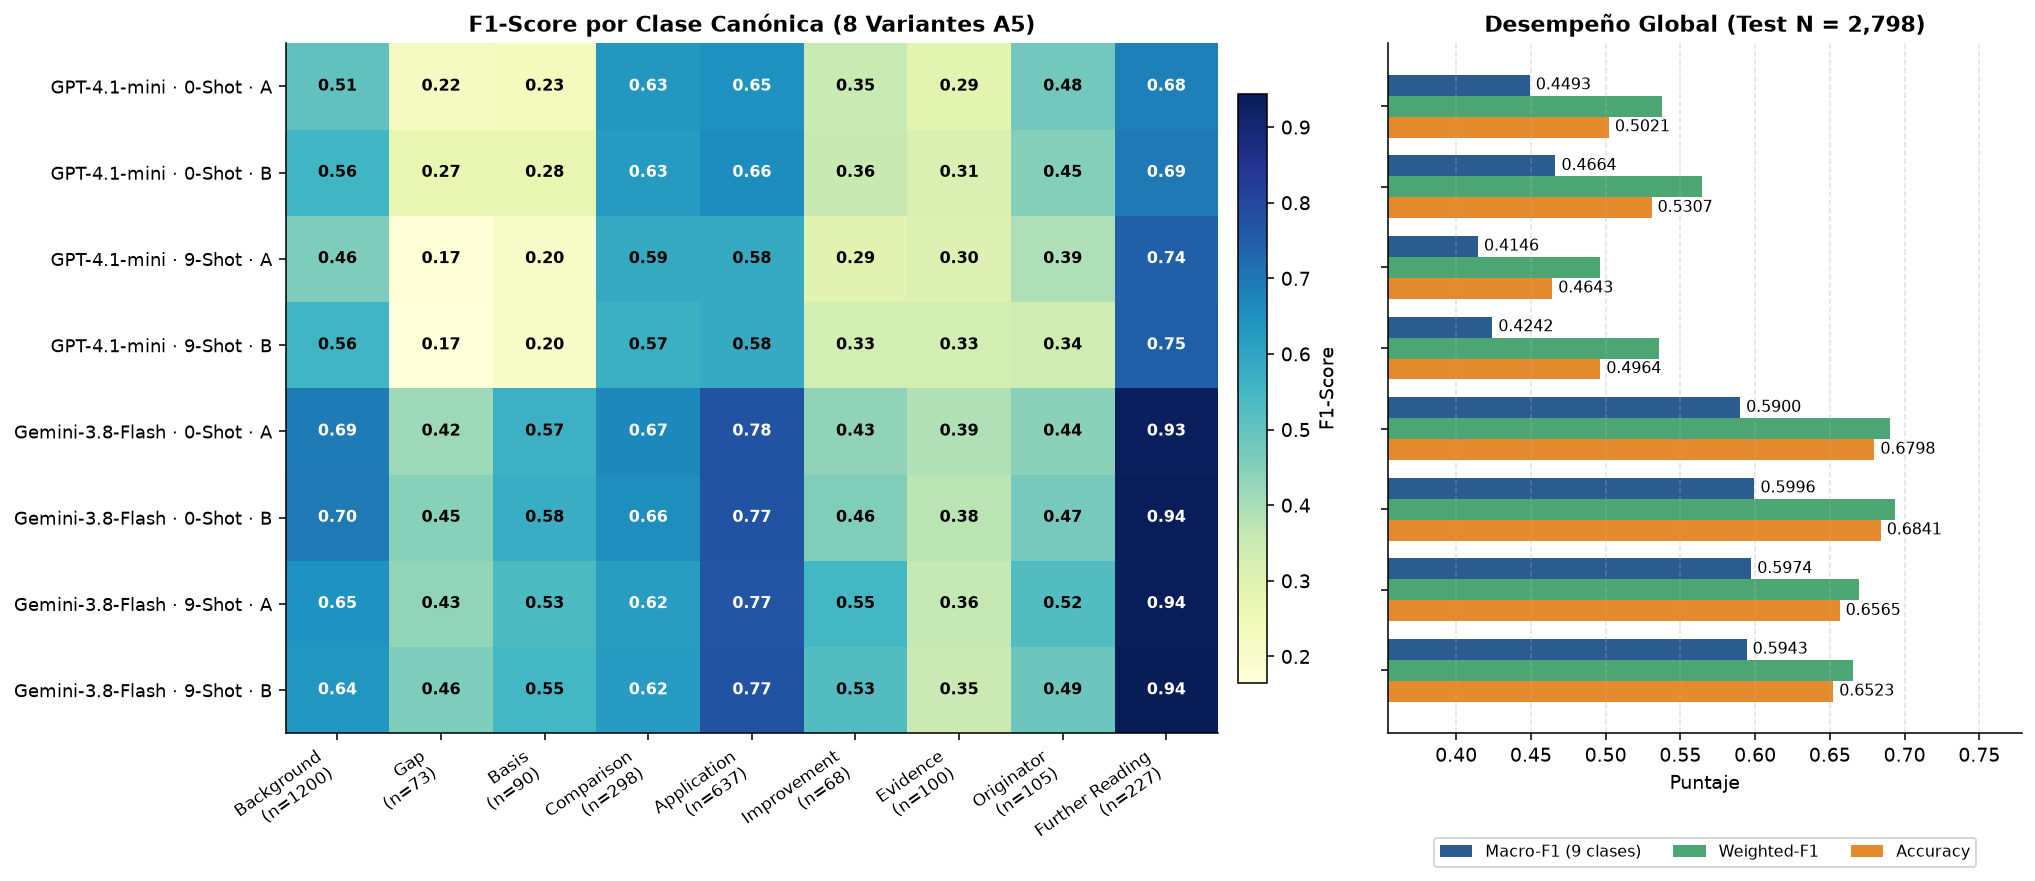

In [5]:
# Tabla F1 por clase across 8 variantes + Macro-F1
f1_class_rows = []
support_dict = runs['gpt41_zs_a']['a6']['per_class_support']
for cls_name in CANONICAL_9_CLASSES:
    row = {'Clase': cls_name, 'Soporte': support_dict[cls_name]}
    for vid, label, *_ in VARIANTS:
        row[label] = runs[vid]['a6']['per_class_f1'][cls_name]
    f1_class_rows.append(row)

df_f1_cls = pd.DataFrame(f1_class_rows)
short_names = {label: f"{m.split('-')[0].upper()}-{s}s-{c}" for _, label, _, _, m, s, c, _ in VARIANTS}
display(df_f1_cls.style.format({c: '{:.4f}' for c in df_f1_cls.columns if c not in ('Clase', 'Soporte')})
        .background_gradient(subset=[c for c in df_f1_cls.columns if c not in ('Clase', 'Soporte')], cmap='YlGnBu', vmin=0.2, vmax=0.85))

# Figura 2: Heatmap F1 por clase + barras comparativas globales
fig = plt.figure(figsize=(16.0, 6.4))
gs = fig.add_gridspec(1, 2, width_ratios=[1.55, 1.0], wspace=0.15)

ax0 = fig.add_subplot(gs[0, 0])
mat_f1 = df_f1_cls[[v[1] for v in VARIANTS]].to_numpy().T  # 8 x 9
hm_vmin = min(0.20, float(mat_f1.min()))
hm_vmax = max(0.85, float(mat_f1.max()))
im = ax0.imshow(mat_f1, cmap='YlGnBu', aspect='auto', vmin=hm_vmin, vmax=hm_vmax)
ax0.set_xticks(np.arange(len(CANONICAL_9_CLASSES)))
ax0.set_xticklabels([f"{c}\n(n={support_dict[c]})" for c in CANONICAL_9_CLASSES], rotation=35, ha='right', fontsize=8.5)
ax0.set_yticks(np.arange(len(VARIANTS)))
ax0.set_yticklabels([v[1] for v in VARIANTS], fontsize=9)
ax0.set_title('F1-Score por Clase Canónica (8 Variantes A5)')
hm_mid = (hm_vmin + hm_vmax) / 2.0 + 0.05
for i in range(mat_f1.shape[0]):
    for j in range(mat_f1.shape[1]):
        val = mat_f1[i, j]
        ax0.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8,
                 color='white' if val > hm_mid else 'black', fontweight='bold')
fig.colorbar(im, ax=ax0, fraction=0.03, pad=0.02, label='F1-Score')

ax1 = fig.add_subplot(gs[0, 1])
y_pos = np.arange(len(VARIANTS))
h = 0.26
ax1.barh(y_pos - h, df_summary['Macro-F1'], height=h, color='#2b5c8f', label='Macro-F1 (9 clases)')
ax1.barh(y_pos,     df_summary['Weighted-F1'], height=h, color='#4ca674', label='Weighted-F1')
ax1.barh(y_pos + h, df_summary['Accuracy'], height=h, color='#e68a2e', label='Accuracy')
for idx, row in df_summary.iterrows():
    ax1.text(row['Macro-F1'] + 0.004, idx - h, f"{row['Macro-F1']:.4f}", va='center', fontsize=8)
    ax1.text(row['Accuracy'] + 0.004, idx + h, f"{row['Accuracy']:.4f}", va='center', fontsize=8)
ax1.set_yticks(y_pos)
ax1.set_yticklabels([])
ax1.invert_yaxis()
min_bar = float(df_summary[['Macro-F1', 'Weighted-F1', 'Accuracy']].min().min())
max_bar = float(df_summary[['Macro-F1', 'Weighted-F1', 'Accuracy']].max().max())
ax1.set_xlim(max(0.0, min_bar - 0.06), min(1.0, max_bar + 0.085))
ax1.set_xlabel('Puntaje')
ax1.set_title('Desempeño Global (Test N = 2,798)')
ax1.grid(axis='x', linestyle='--', alpha=0.35)
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8.3, frameon=True)

fig.savefig(FIG_DIR / 'fig02_desempeno_global_y_por_clase.png', bbox_inches='tight')
plt.show()


Distribución de macro-secciones en Test Gold:
macro_section
Otras secciones        1356
Intro / Prelim          551
Method / Setup          362
Experiments / Eval      273
Related Work            214
Conclusion / Future      42
Name: count, dtype: int64


Variante,GPT-4.1-mini · 0-Shot · A,GPT-4.1-mini · 0-Shot · B,GPT-4.1-mini · 9-Shot · A,GPT-4.1-mini · 9-Shot · B,Gemini-3.8-Flash · 0-Shot · A,Gemini-3.8-Flash · 0-Shot · B,Gemini-3.8-Flash · 9-Shot · A,Gemini-3.8-Flash · 9-Shot · B
Macro-Sección,,,,,,,,
Conclusion / Future (n=42),0.4286,0.4048,0.3571,0.3095,0.7143,0.7619,0.6667,0.6190
Experiments / Eval (n=273),0.5201,0.5128,0.5092,0.5092,0.6557,0.6484,0.6300,0.6300
Intro / Prelim (n=551),0.4955,0.5426,0.4682,0.5481,0.7368,0.7495,0.7205,0.7060
Method / Setup (n=362),0.5746,0.6077,0.4972,0.4945,0.7155,0.7320,0.7017,0.6989
Otras secciones (n=1356),0.4978,0.5147,0.4580,0.4838,0.6504,0.6490,0.6195,0.6158
Related Work (n=214),0.4159,0.5187,0.4019,0.4673,0.6822,0.6869,0.6822,0.7009



Top 10 confusiones en Gemini-3.8-Flash · 0-Shot · B (mejor Gemini, Macro-F1=0.5996):


,Real,Predicho,Errores,% Fila Real
0,Background,Application,125,10.416667
1,Background,Comparison,114,9.500000
2,Background,Originator,69,5.750000
3,Background,Evidence,60,5.000000
4,Background,Gap,53,4.416667
5,Background,Basis,47,3.916667
6,Application,Basis,41,6.436421
7,Application,Comparison,37,5.808477
8,Background,Improvement,33,2.750000
9,Originator,Background,27,25.714286



Top 10 confusiones en GPT-4.1-mini · 0-Shot · B (mejor OpenAI, Macro-F1=0.4664):


,Real,Predicho,Errores,% Fila Real
0,Background,Basis,207,17.250000
1,Background,Evidence,152,12.666667
2,Application,Basis,134,21.036107
3,Background,Application,111,9.250000
4,Background,Comparison,106,8.833333
5,Further Reading,Background,70,30.837004
6,Application,Comparison,60,9.419152
7,Comparison,Evidence,47,15.771812
8,Background,Gap,36,3.000000
9,Originator,Basis,36,34.285714


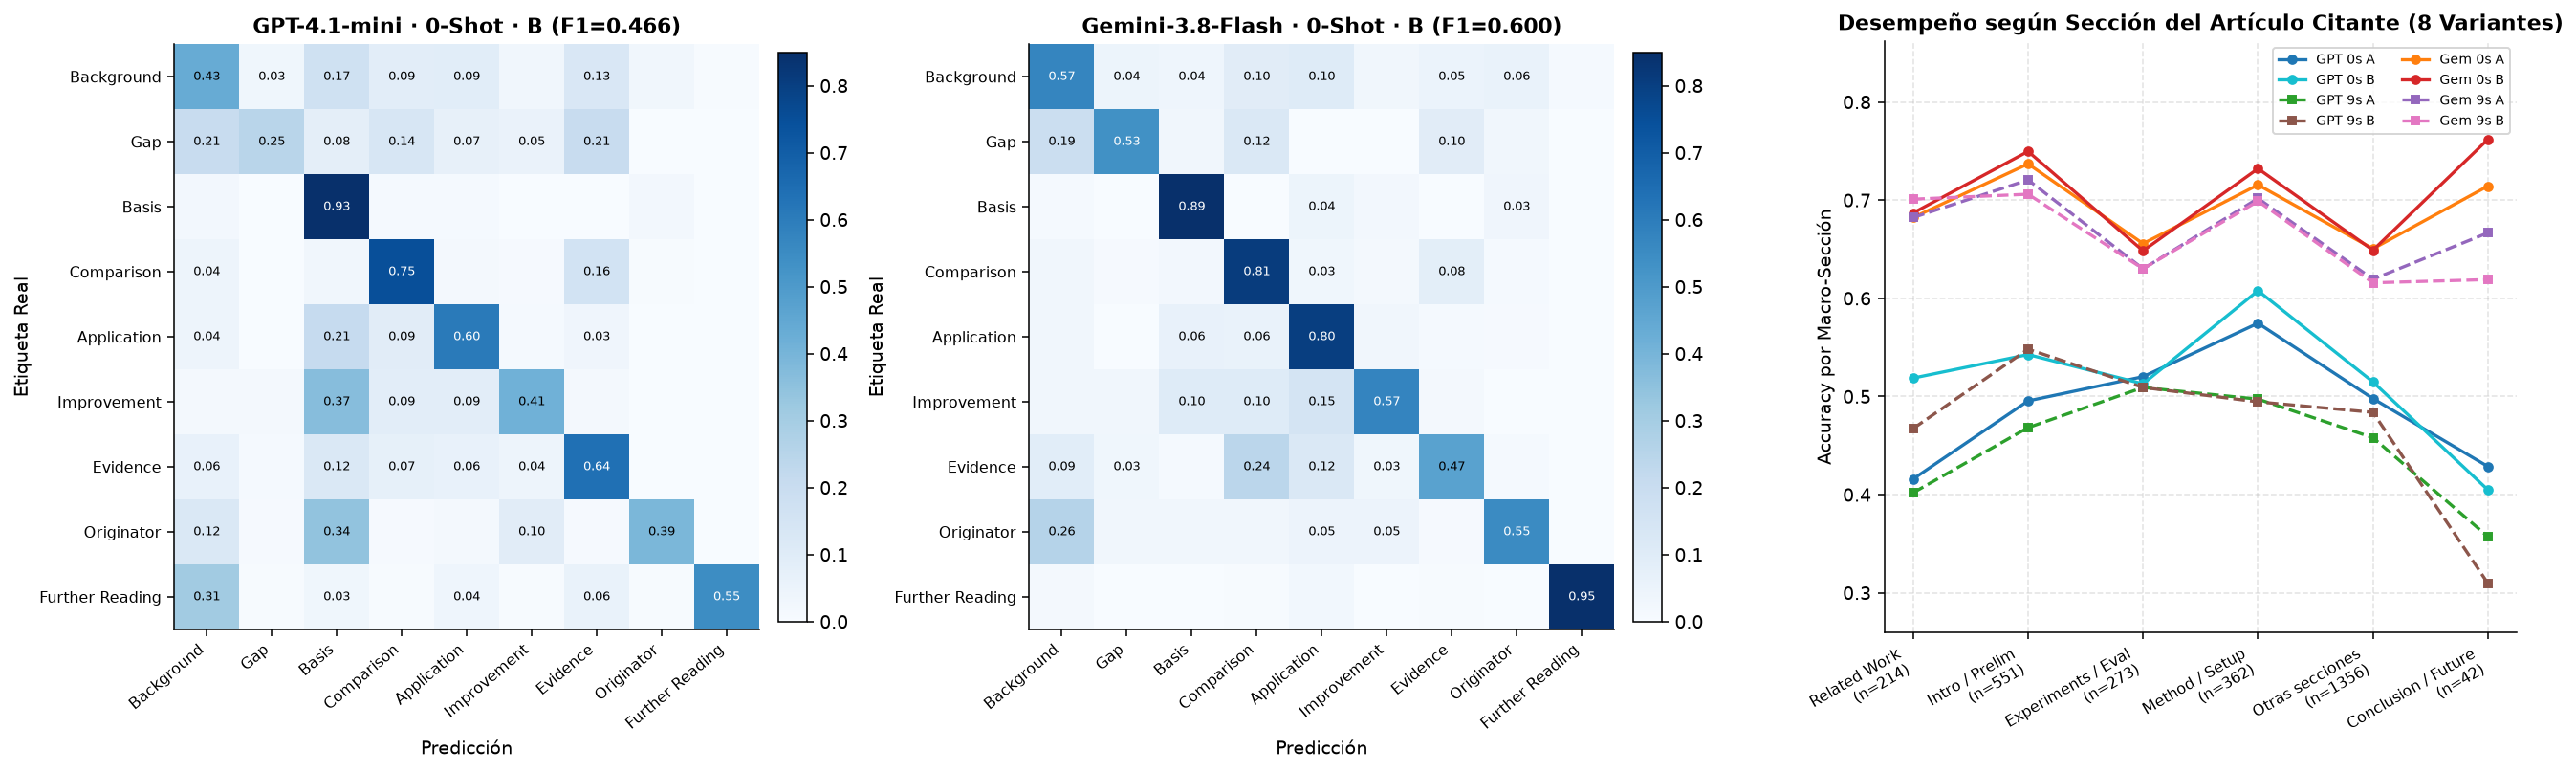

In [6]:
# Análisis por sección retórica citante (citing_section) y principales pares de confusión
def map_macro_section(sec):
    if sec is None or (isinstance(sec, float) and np.isnan(sec)):
        return 'Sin sección (null)'
    s = str(sec).lower()
    if any(k in s for k in ('intro', 'motivation', 'overview', 'prelimin', 'backgr')):
        return 'Intro / Prelim'
    if any(k in s for k in ('related', 'literat', 'prior', 'previous')):
        return 'Related Work'
    if any(k in s for k in ('method', 'approach', 'model', 'architect', 'algorith', 'framework', 'system', 'implement', 'train', 'setup')):
        return 'Method / Setup'
    if any(k in s for k in ('experim', 'evaluat', 'result', 'ablation', 'discuss', 'analysis', 'benchmark', 'compar')):
        return 'Experiments / Eval'
    if any(k in s for k in ('conclu', 'future', 'limit', 'summary')):
        return 'Conclusion / Future'
    return 'Otras secciones'

df_all['macro_section'] = df_all['citing_section'].map(map_macro_section)
gold_df['macro_section'] = gold_df['citing_section'].map(map_macro_section)
sec_counts = gold_df['macro_section'].value_counts()
print('Distribución de macro-secciones en Test Gold:')
print(sec_counts)

sec_perf = []
for ms_name, cnt in sec_counts.items():
    for vid, label, *_ in VARIANTS:
        sub = df_all[(df_all['vid'] == vid) & (df_all['macro_section'] == ms_name)]
        sec_perf.append({
            'Macro-Sección': f"{ms_name} (n={cnt})",
            'ms_raw': ms_name,
            'n': int(cnt),
            'Variante': label,
            'vid': vid,
            'Accuracy': sub['is_correct'].mean(),
            'Macro-F1': f1_score(sub['y_true_idx'], sub['y_pred_idx'], labels=list(range(9)), average='macro', zero_division=0),
        })
df_sec = pd.DataFrame(sec_perf)
piv_sec = df_sec.pivot(index='Macro-Sección', columns='Variante', values='Accuracy')
display(piv_sec[[v[1] for v in VARIANTS]].style.format('{:.4f}').background_gradient(cmap='Blues', axis=None))

# Top pares de confusión en los dos mejores representantes por familia (selección dinámica)
def top_confusions(vid, top_k=10):
    cm = np.array(runs[vid]['a6']['confusion_matrix'], dtype=int)
    pairs = []
    for i, c_true in enumerate(CANONICAL_9_CLASSES):
        for j, c_pred in enumerate(CANONICAL_9_CLASSES):
            if i != j and cm[i, j] > 0:
                pairs.append((c_true, c_pred, int(cm[i, j]), cm[i, j] / max(1, cm[i].sum()) * 100.0))
    pairs.sort(key=lambda x: x[2], reverse=True)
    return pd.DataFrame(pairs[:top_k], columns=['Real', 'Predicho', 'Errores', '% Fila Real'])

best_gpt_row = df_summary[df_summary['Modelo'] == 'gpt-4.1-mini'].sort_values('Macro-F1', ascending=False).iloc[0]
best_gem_row = df_summary[df_summary['Modelo'] == 'gemini-3.8-flash'].sort_values('Macro-F1', ascending=False).iloc[0]

print(f"\nTop 10 confusiones en {best_gem_row['Variante']} (mejor Gemini, Macro-F1={best_gem_row['Macro-F1']:.4f}):")
display(top_confusions(best_gem_row['vid']))
print(f"\nTop 10 confusiones en {best_gpt_row['Variante']} (mejor OpenAI, Macro-F1={best_gpt_row['Macro-F1']:.4f}):")
display(top_confusions(best_gpt_row['vid']))

# Figura 3: Matrices de confusión de los mejores exponentes + Accuracy por macro-sección citante (8 variantes)
fig, axes = plt.subplots(1, 3, figsize=(19.0, 5.8))

for ax, brow in [
    (axes[0], best_gpt_row),
    (axes[1], best_gem_row),
]:
    vid = brow['vid']
    title_cm = f"{brow['Variante']} (F1={brow['Macro-F1']:.3f})"
    cm = np.array(runs[vid]['a6']['confusion_matrix'], dtype=float)
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1.0)
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0.0, vmax=0.85)
    ax.set_title(title_cm)
    ax.set_xticks(range(9)); ax.set_yticks(range(9))
    ax.set_xticklabels(CANONICAL_9_CLASSES, rotation=40, ha='right', fontsize=8)
    ax.set_yticklabels(CANONICAL_9_CLASSES, fontsize=8)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta Real')
    for i in range(9):
        for j in range(9):
            val = cm_norm[i, j]
            if val >= 0.03 or i == j:
                ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=6.8,
                        color='white' if val > 0.48 else 'black')
    fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)

ax2 = axes[2]
sec_order = ['Related Work', 'Intro / Prelim', 'Experiments / Eval', 'Method / Setup', 'Otras secciones', 'Conclusion / Future', 'Sin sección (null)']
sec_order = [s for s in sec_order if s in set(df_sec['ms_raw'])]
x_s = np.arange(len(sec_order))
for vid, _, _, _, mod_n, sh, cfg, _ in VARIANTS:
    vals = [df_sec[(df_sec['vid'] == vid) & (df_sec['ms_raw'] == s)]['Accuracy'].iloc[0] for s in sec_order]
    short_lbl = f"{'GPT' if 'gpt' in mod_n else 'Gem'} {sh}s {cfg}"
    ls_style = '-' if sh == 0 else '--'
    mk_style = 'o' if sh == 0 else 's'
    ax2.plot(x_s, vals, marker=mk_style, linestyle=ls_style, linewidth=1.7, markersize=4.5, label=short_lbl, color=COLORS[vid])
ax2.set_xticks(x_s)
ax2.set_xticklabels([f"{s}\n(n={sec_counts[s]})" for s in sec_order], rotation=30, ha='right', fontsize=8)
ax2.set_ylabel('Accuracy por Macro-Sección')
ax2.set_title('Desempeño según Sección del Artículo Citante (8 Variantes)')
sec_min, sec_max = float(df_sec['Accuracy'].min()), float(df_sec['Accuracy'].max())
ax2.set_ylim(max(0.0, sec_min - 0.05), min(1.0, sec_max + 0.10))
ax2.grid(linestyle='--', alpha=0.35)
ax2.legend(fontsize=7.2, ncol=2, frameon=True, loc='upper right')

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig03_confusiones_criticas_y_seccion_citante.png', bbox_inches='tight')
plt.show()


## 4. Pruebas Formales de Significancia Estadística Pareada ($B = 10{,}000$)

Se ejecuta `src.modeling.evaluate.paired_significance_test` (*Paired Bootstrap* bilateral + prueba exacta/chi2 de *McNemar* sobre discordancias $n_{01}, n_{10}$) para los **12 contrastes ortogonales** del experimento ($4$ pares Config B vs. A, $4$ pares 9-Shot vs. 0-Shot y $4$ pares Gemini vs. GPT), aplicando además ajuste **Holm-Bonferroni** ($\alpha = 0.05$) por comparaciones múltiples.


,Bloque,Contraste,F1 (Base A),F1 (Comp B),Δ F1 (B - A),IC 95% Bootstrap,p (Bootstrap),Sig Holm-Bonf (Boot),n10 (Solo A ✓),n01 (Solo B ✓),p (McNemar),Sig Holm-Bonf (McN)
0,Config B vs. Config A,GPT-4.1-mini · 0-Shot (B vs A),0.4493,0.4664,+0.0172,"[+0.0007, +0.0332]",3.6800e-02,NO,114,194,6.7494e-06,SÍ
1,Config B vs. Config A,GPT-4.1-mini · 9-Shot (B vs A),0.4146,0.4242,+0.0096,"[-0.0060, +0.0255]",2.3960e-01,NO,167,257,1.5447e-05,SÍ
2,Config B vs. Config A,Gemini-3.8-Flash · 0-Shot (B vs A),0.5900,0.5996,+0.0096,"[-0.0025, +0.0218]",1.2190e-01,NO,62,74,3.4556e-01,NO
3,Config B vs. Config A,Gemini-3.8-Flash · 9-Shot (B vs A),0.5974,0.5943,-0.0031,"[-0.0148, +0.0081]",5.9240e-01,NO,96,84,4.1228e-01,NO
4,9-Shot vs. 0-Shot,GPT-4.1-mini · Config A (9s vs 0s),0.4493,0.4146,-0.0347,"[-0.0557, -0.0139]",7.0000e-04,SÍ,325,219,6.7368e-06,SÍ
5,9-Shot vs. 0-Shot,GPT-4.1-mini · Config B (9s vs 0s),0.4664,0.4242,-0.0423,"[-0.0643, -0.0208]",1.0000e-04,SÍ,325,229,5.4332e-05,SÍ
6,9-Shot vs. 0-Shot,Gemini-3.8-Flash · Config A (9s vs 0s),0.5900,0.5974,+0.0075,"[-0.0086, +0.0239]",3.6400e-01,NO,171,106,1.2036e-04,SÍ
7,9-Shot vs. 0-Shot,Gemini-3.8-Flash · Config B (9s vs 0s),0.5996,0.5943,-0.0053,"[-0.0202, +0.0104]",5.0540e-01,NO,182,93,1.1169e-07,SÍ
8,Gemini vs. GPT-4.1-mini,0-Shot · Config A (Gem vs GPT),0.4493,0.5900,+0.1407,"[+0.1156, +0.1658]",0.0000e+00,SÍ,150,647,4.2395e-69,SÍ
9,Gemini vs. GPT-4.1-mini,0-Shot · Config B (Gem vs GPT),0.4664,0.5996,+0.1331,"[+0.1084, +0.1573]",0.0000e+00,SÍ,168,597,5.1675e-54,SÍ


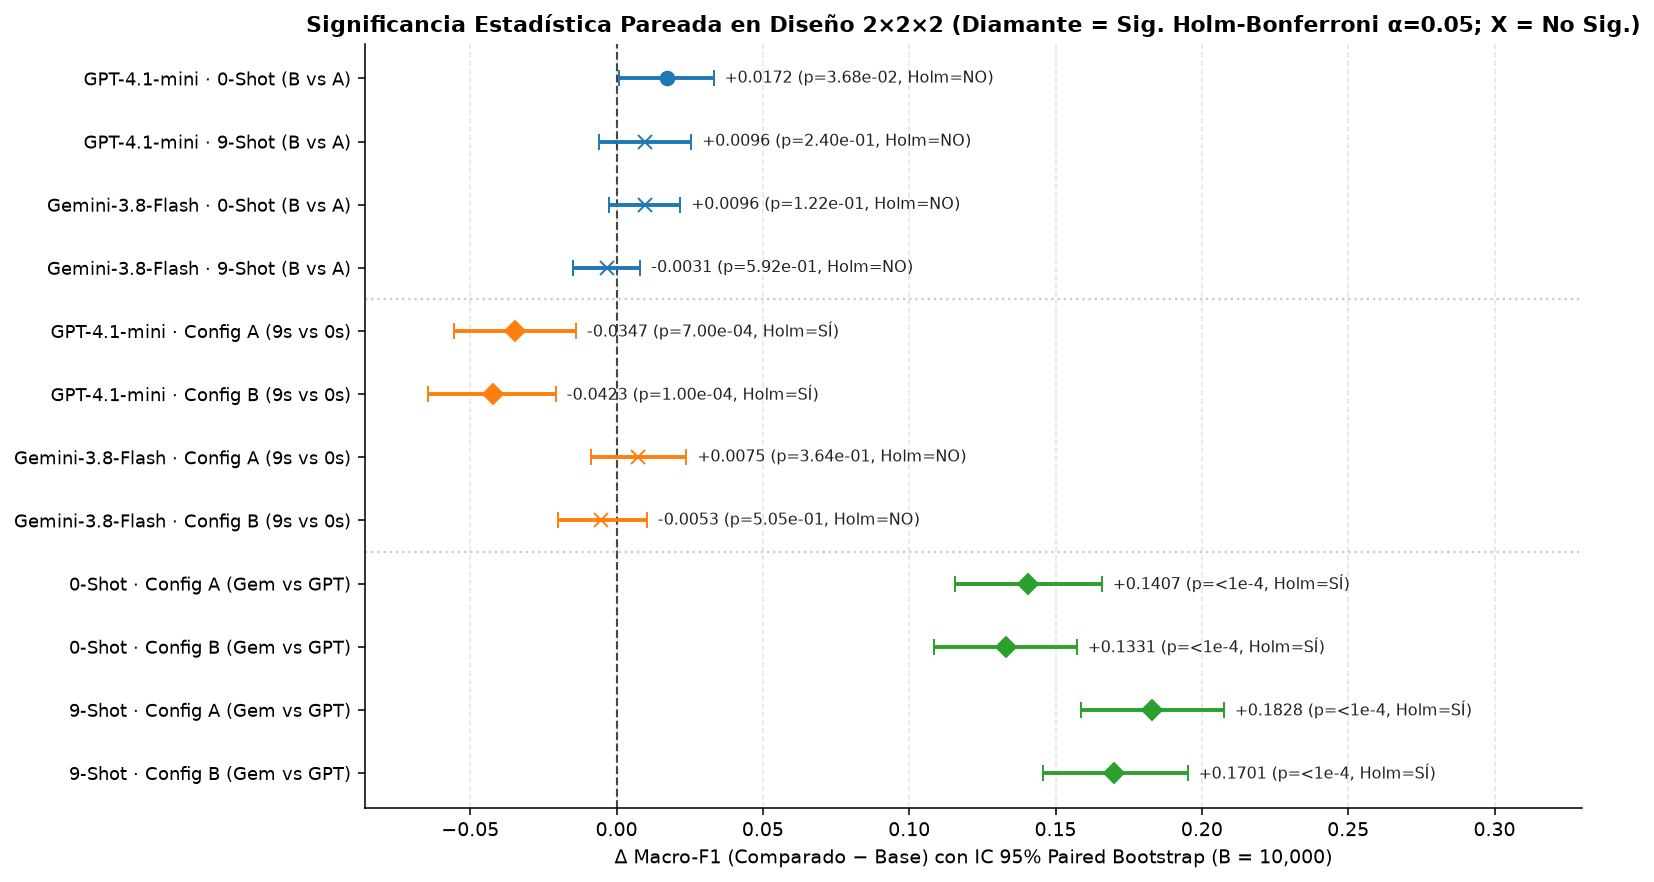

In [7]:
CONTRASTS = [
    # Bloque 1: Config B - Config A (Hipótesis RAG Retórico)
    ('Config B vs. Config A', 'GPT-4.1-mini · 0-Shot (B vs A)',     'gpt41_zs_a',  'gpt41_zs_b'),
    ('Config B vs. Config A', 'GPT-4.1-mini · 9-Shot (B vs A)',     'gpt41_fs_a',  'gpt41_fs_b'),
    ('Config B vs. Config A', 'Gemini-3.8-Flash · 0-Shot (B vs A)', 'gemini_zs_a', 'gemini_zs_b'),
    ('Config B vs. Config A', 'Gemini-3.8-Flash · 9-Shot (B vs A)', 'gemini_fs_a', 'gemini_fs_b'),
    # Bloque 2: Few-Shot (9) vs Zero-Shot (0)
    ('9-Shot vs. 0-Shot', 'GPT-4.1-mini · Config A (9s vs 0s)',     'gpt41_zs_a',  'gpt41_fs_a'),
    ('9-Shot vs. 0-Shot', 'GPT-4.1-mini · Config B (9s vs 0s)',     'gpt41_zs_b',  'gpt41_fs_b'),
    ('9-Shot vs. 0-Shot', 'Gemini-3.8-Flash · Config A (9s vs 0s)', 'gemini_zs_a', 'gemini_fs_a'),
    ('9-Shot vs. 0-Shot', 'Gemini-3.8-Flash · Config B (9s vs 0s)', 'gemini_zs_b', 'gemini_fs_b'),
    # Bloque 3: Gemini-3.8-Flash vs GPT-4.1-mini
    ('Gemini vs. GPT-4.1-mini', '0-Shot · Config A (Gem vs GPT)',   'gpt41_zs_a',  'gemini_zs_a'),
    ('Gemini vs. GPT-4.1-mini', '0-Shot · Config B (Gem vs GPT)',   'gpt41_zs_b',  'gemini_zs_b'),
    ('Gemini vs. GPT-4.1-mini', '9-Shot · Config A (Gem vs GPT)',   'gpt41_fs_a',  'gemini_fs_a'),
    ('Gemini vs. GPT-4.1-mini', '9-Shot · Config B (Gem vs GPT)',   'gpt41_fs_b',  'gemini_fs_b'),
]

sig_rows = []
for blk, cname, vid_a, vid_b in CONTRASTS:
    res = paired_significance_test(
        y_true=y_true,
        y_pred_a=runs[vid_a]['y_pred'],
        y_pred_b=runs[vid_b]['y_pred'],
        n_bootstrap=10000,
        seed=42,
    )
    sig_rows.append({
        'Bloque': blk,
        'Contraste': cname,
        'vid_a': vid_a,
        'vid_b': vid_b,
        'F1 (Base A)': res.score_a,
        'F1 (Comp B)': res.score_b,
        'Δ F1 (B - A)': res.delta_b_minus_a,
        'IC95_low': res.ci_95_low,
        'IC95_high': res.ci_95_high,
        'IC 95% Bootstrap': f'[{res.ci_95_low:+.4f}, {res.ci_95_high:+.4f}]',
        'p (Bootstrap)': res.p_value_bootstrap,
        'n10 (Solo A ✓)': res.mcnemar_a_only_correct,
        'n01 (Solo B ✓)': res.mcnemar_b_only_correct,
        'p (McNemar)': res.p_value_mcnemar,
        'Sig α=0.05': 'SÍ' if res.is_significant_95 else 'NO',
    })

df_sig_all = pd.DataFrame(sig_rows)

# Corrección Holm-Bonferroni (m=12 pruebas)
for col_p, col_adj in [('p (Bootstrap)', 'Sig Holm-Bonf (Boot)'), ('p (McNemar)', 'Sig Holm-Bonf (McN)')]:
    pvals = df_sig_all[col_p].to_numpy()
    order = np.argsort(pvals)
    m = len(pvals)
    rejected = np.zeros(m, dtype=bool)
    for rank, idx in enumerate(order):
        if pvals[idx] <= 0.05 / (m - rank):
            rejected[idx] = True
        else:
            break
    df_sig_all[col_adj] = np.where(rejected, 'SÍ', 'NO')

display(df_sig_all[[
    'Bloque', 'Contraste', 'F1 (Base A)', 'F1 (Comp B)', 'Δ F1 (B - A)', 'IC 95% Bootstrap',
    'p (Bootstrap)', 'Sig Holm-Bonf (Boot)', 'n10 (Solo A ✓)', 'n01 (Solo B ✓)', 'p (McNemar)', 'Sig Holm-Bonf (McN)'
]].style.format({
    'F1 (Base A)': '{:.4f}', 'F1 (Comp B)': '{:.4f}', 'Δ F1 (B - A)': '{:+.4f}',
    'p (Bootstrap)': '{:.4e}', 'p (McNemar)': '{:.4e}',
}))

# Figura 4: Forest Plot de los 12 contrastes pareados
fig, ax = plt.subplots(figsize=(11.5, 6.4))
y_idx = np.arange(len(df_sig_all))
ax.axvline(0.0, color='black', linestyle='--', linewidth=1.1, alpha=0.7)

blk_colors = {
    'Config B vs. Config A': '#1f77b4',
    '9-Shot vs. 0-Shot': '#ff7f0e',
    'Gemini vs. GPT-4.1-mini': '#2ca02c',
}

for i, r in df_sig_all.iterrows():
    c = blk_colors[r['Bloque']]
    marker = 'D' if r['Sig Holm-Bonf (Boot)'] == 'SÍ' else ('o' if r['Sig α=0.05'] == 'SÍ' else 'x')
    ax.errorbar(
        r['Δ F1 (B - A)'], i,
        xerr=[[r['Δ F1 (B - A)'] - r['IC95_low']], [r['IC95_high'] - r['Δ F1 (B - A)']]],
        fmt=marker, color=c, ecolor=c, elinewidth=2.0, capsize=4, markersize=7,
    )
    p_str = '<1e-4' if r['p (Bootstrap)'] == 0.0 else f"{r['p (Bootstrap)']:.2e}"
    txt_sig = f" {r['Δ F1 (B - A)']:+.4f} (p={p_str}, Holm={r['Sig Holm-Bonf (Boot)']})"
    ax.text(max(r['IC95_high'], r['Δ F1 (B - A)']) + 0.002, i, txt_sig, va='center', fontsize=8.3, color='#222')

ax.axhline(3.5, color='#ccc', linestyle=':', linewidth=1.2)
ax.axhline(7.5, color='#ccc', linestyle=':', linewidth=1.2)
ax.set_yticks(y_idx)
ax.set_yticklabels(df_sig_all['Contraste'], fontsize=9)
ax.invert_yaxis()
sig_min_x = float(df_sig_all[['IC95_low', 'Δ F1 (B - A)']].min().min())
sig_max_x = float(df_sig_all[['IC95_high', 'Δ F1 (B - A)']].max().max())
sig_span = max(0.05, sig_max_x - sig_min_x)
ax.set_xlim(sig_min_x - sig_span * 0.08, sig_max_x + sig_span * 0.45)
ax.set_xlabel('Δ Macro-F1 (Comparado − Base) con IC 95% Paired Bootstrap (B = 10,000)')
ax.set_title('Significancia Estadística Pareada en Diseño 2×2×2 (Diamante = Sig. Holm-Bonferroni α=0.05; X = No Sig.)')
ax.grid(axis='x', linestyle='--', alpha=0.35)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig04_forest_plot_significancia_pareada.png', bbox_inches='tight')
plt.show()


## 5. Eje 1C (Opción 2): Calibración Probabilística (`ECE`, `MCE`, `Brier Score`) y Verificación de `ARQ-09 §5.1`

Conforme a `ARQ-09 §5.1`, las probabilidades de A5 son **confianza verbalizada estructurada** normalizada a $\Delta^8$ por `NineClassScores.to_dict_canonical()`. Aquí evaluamos su calibración formal con:
* **ECE** (*Expected Calibration Error*, $M=10$ bins equiespaciados sobre confianza top-1 $p_{\max}$).
* **MCE** (*Maximum Calibration Error*) en bins totales y filtrados ($n_b \ge 10$ para estabilidad muestral).
* **Brier Score Multiclase** ($\text{BS} = \frac{1}{N} \sum_{i=1}^N \sum_{c=1}^9 (p_{i,c} - y_{i,c})^2 \in [0, 2]$) y **NLL** (*Negative Log-Likelihood*).
* **Brecha de Sobreconfianza** ($\bar{p}_{\text{err}} - \bar{p}_{\text{acierto}}$) y contraste directo **0-Shot vs. 9-Shot con `_RHETORICAL_NEIGHBORS`** (*anclaje discreto* vs. *distribución graduada*).


In [8]:
def compute_calibration_metrics(probs: np.ndarray, y_true_i: np.ndarray, y_pred_i: np.ndarray, n_bins: int = 10):
    conf = probs.max(axis=1)
    correct = (y_pred_i == y_true_i).astype(np.float64)
    n = len(y_true_i)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce_all = 0.0
    mce_min10 = 0.0
    bin_stats = []
    for b in range(n_bins):
        lo, hi = bins[b], bins[b + 1]
        if b == 0:
            mask = (conf >= lo) & (conf <= hi)
        else:
            mask = (conf > lo) & (conf <= hi)
        cnt = int(mask.sum())
        if cnt > 0:
            acc_b = float(correct[mask].mean())
            conf_b = float(conf[mask].mean())
            gap = abs(acc_b - conf_b)
            ece += (cnt / n) * gap
            mce_all = max(mce_all, gap)
            if cnt >= 10:
                mce_min10 = max(mce_min10, gap)
        else:
            acc_b, conf_b, gap = np.nan, np.nan, np.nan
        bin_stats.append({'bin': b, 'lo': lo, 'hi': hi, 'n': cnt, 'acc': acc_b, 'conf': conf_b, 'gap': gap})

    # Brier Score multiclase (rango [0, 2]) y Top-1 Brier
    one_hot = np.eye(probs.shape[1], dtype=np.float64)[y_true_i]
    brier_multi = float(np.mean(np.sum((probs - one_hot) ** 2, axis=1)))
    brier_top1 = float(np.mean((conf - correct) ** 2))

    # NLL y entropía de Shannon media (nats)
    p_true = np.clip(probs[np.arange(n), y_true_i], 1e-12, 1.0)
    nll = float(-np.mean(np.log(p_true)))
    p_safe = np.clip(probs, 1e-12, 1.0)
    entropy_nats = float(np.mean(-np.sum(probs * np.log(p_safe), axis=1)))

    mean_conf = float(conf.mean())
    acc_total = float(correct.mean())
    conf_ok = float(conf[correct == 1].mean()) if (correct == 1).any() else np.nan
    conf_err = float(conf[correct == 0].mean()) if (correct == 0).any() else np.nan

    # Telemetría de anclaje numérico ARQ-09 §5.1
    top1_unique = len(np.unique(np.round(conf, 4)))
    zero_mass_pct = float((probs == 0.0).mean() * 100.0)
    max_probs_top3_share = sum(v for _, v in Counter(np.round(conf, 3)).most_common(3)) / n * 100.0

    return {
        'ECE': float(ece),
        'MCE (todos bins)': float(mce_all),
        'MCE (bins n>=10)': float(mce_min10),
        'Brier Multiclase': brier_multi,
        'Brier Top-1': brier_top1,
        'NLL': nll,
        'Entropía (nats)': entropy_nats,
        'Accuracy': acc_total,
        'Conf Media': mean_conf,
        'Sobreconfianza (Conf-Acc)': mean_conf - acc_total,
        'Conf | Acierto': conf_ok,
        'Conf | Error': conf_err,
        'Δ Conf (Ok-Err)': conf_ok - conf_err,
        'Top3 Modas Conf (%)': max_probs_top3_share,
        'Ceros en Vector (%)': zero_mass_pct,
        'Valores Únicos Conf': top1_unique,
        'bin_stats': pd.DataFrame(bin_stats),
    }

calib_rows = []
calib_bins = {}
for vid, rinfo in runs.items():
    cm = compute_calibration_metrics(rinfo['probs'], y_true_idx, rinfo['y_pred_idx'], n_bins=10)
    calib_bins[vid] = cm.pop('bin_stats')
    calib_rows.append({'vid': vid, 'Variante': rinfo['label'], 'Modelo': rinfo['model'], 'Shots': rinfo['shots'], 'Config': rinfo['cfg'], **cm})

df_calib = pd.DataFrame(calib_rows)
display(df_calib[[
    'Variante', 'ECE', 'MCE (todos bins)', 'MCE (bins n>=10)', 'Brier Multiclase', 'NLL',
    'Accuracy', 'Conf Media', 'Sobreconfianza (Conf-Acc)', 'Conf | Acierto', 'Conf | Error', 'Δ Conf (Ok-Err)',
    'Top3 Modas Conf (%)', 'Ceros en Vector (%)'
]].style.format({
    'ECE': '{:.4f}', 'MCE (todos bins)': '{:.4f}', 'MCE (bins n>=10)': '{:.4f}',
    'Brier Multiclase': '{:.4f}', 'NLL': '{:.4f}', 'Accuracy': '{:.4f}',
    'Conf Media': '{:.4f}', 'Sobreconfianza (Conf-Acc)': '{:+.4f}',
    'Conf | Acierto': '{:.4f}', 'Conf | Error': '{:.4f}', 'Δ Conf (Ok-Err)': '{:+.4f}',
    'Top3 Modas Conf (%)': '{:.1f}%', 'Ceros en Vector (%)': '{:.1f}%',
}))

# Pruebas pareadas Bootstrap/Wilcoxon en Brier Score y Confianza: 9-Shot vs 0-Shot
print('\nContraste 9-Shot vs. 0-Shot en Brier Score individual (Wilcoxon paired signed-rank):')
for name_pair, v0, v9 in [
    ('GPT-4.1-mini · Config A', 'gpt41_zs_a', 'gpt41_fs_a'),
    ('GPT-4.1-mini · Config B', 'gpt41_zs_b', 'gpt41_fs_b'),
    ('Gemini-3.8-Flash · Config A', 'gemini_zs_a', 'gemini_fs_a'),
    ('Gemini-3.8-Flash · Config B', 'gemini_zs_b', 'gemini_fs_b'),
]:
    one_hot = np.eye(9, dtype=np.float64)[y_true_idx]
    b0 = np.sum((runs[v0]['probs'] - one_hot) ** 2, axis=1)
    b9 = np.sum((runs[v9]['probs'] - one_hot) ** 2, axis=1)
    stat_w, p_w = stats.wilcoxon(b9, b0)
    print(f" • {name_pair:<28}: Brier 0s={b0.mean():.4f} → 9s={b9.mean():.4f} (Δ={b9.mean()-b0.mean():+.4f}, Wilcoxon p={p_w:.3e})")


,Variante,ECE,MCE (todos bins),MCE (bins n>=10),Brier Multiclase,NLL,Accuracy,Conf Media,Sobreconfianza (Conf-Acc),Conf | Acierto,Conf | Error,Δ Conf (Ok-Err),Top3 Modas Conf (%),Ceros en Vector (%)
0,GPT-4.1-mini · 0-Shot · A,0.3284,0.7000,0.4560,0.8449,5.6807,0.5021,0.8288,+0.3266,0.8478,0.8095,+0.0383,59.5%,36.3%
1,GPT-4.1-mini · 0-Shot · B,0.3360,0.4598,0.4598,0.8221,6.0666,0.5307,0.8640,+0.3333,0.8806,0.8453,+0.0353,64.8%,40.9%
2,GPT-4.1-mini · 9-Shot · A,0.3282,0.5200,0.3502,0.8531,2.0473,0.4643,0.7919,+0.3277,0.7962,0.7882,+0.0080,52.7%,9.2%
3,GPT-4.1-mini · 9-Shot · B,0.3036,0.4898,0.3836,0.8188,2.0760,0.4964,0.7996,+0.3032,0.8008,0.7984,+0.0024,58.9%,10.8%
4,Gemini-3.8-Flash · 0-Shot · A,0.1204,0.3246,0.3246,0.4834,1.2253,0.6798,0.8000,+0.1202,0.8303,0.7357,+0.0946,36.3%,26.9%
5,Gemini-3.8-Flash · 0-Shot · B,0.1158,0.2852,0.2852,0.4809,1.2778,0.6841,0.7999,+0.1158,0.8290,0.7368,+0.0922,37.4%,28.9%
6,Gemini-3.8-Flash · 9-Shot · A,0.1139,0.4038,0.4038,0.5012,1.0687,0.6565,0.7369,+0.0804,0.7618,0.6894,+0.0724,30.5%,6.5%
7,Gemini-3.8-Flash · 9-Shot · B,0.1257,0.3065,0.3065,0.5114,1.0913,0.6523,0.7453,+0.0931,0.7683,0.7021,+0.0662,32.3%,7.3%



Contraste 9-Shot vs. 0-Shot en Brier Score individual (Wilcoxon paired signed-rank):
 • GPT-4.1-mini · Config A     : Brier 0s=0.8449 → 9s=0.8531 (Δ=+0.0082, Wilcoxon p=9.528e-02)
 • GPT-4.1-mini · Config B     : Brier 0s=0.8221 → 9s=0.8188 (Δ=-0.0033, Wilcoxon p=1.146e-01)
 • Gemini-3.8-Flash · Config A : Brier 0s=0.4834 → 9s=0.5012 (Δ=+0.0178, Wilcoxon p=5.253e-17)
 • Gemini-3.8-Flash · Config B : Brier 0s=0.4809 → 9s=0.5114 (Δ=+0.0305, Wilcoxon p=6.492e-23)


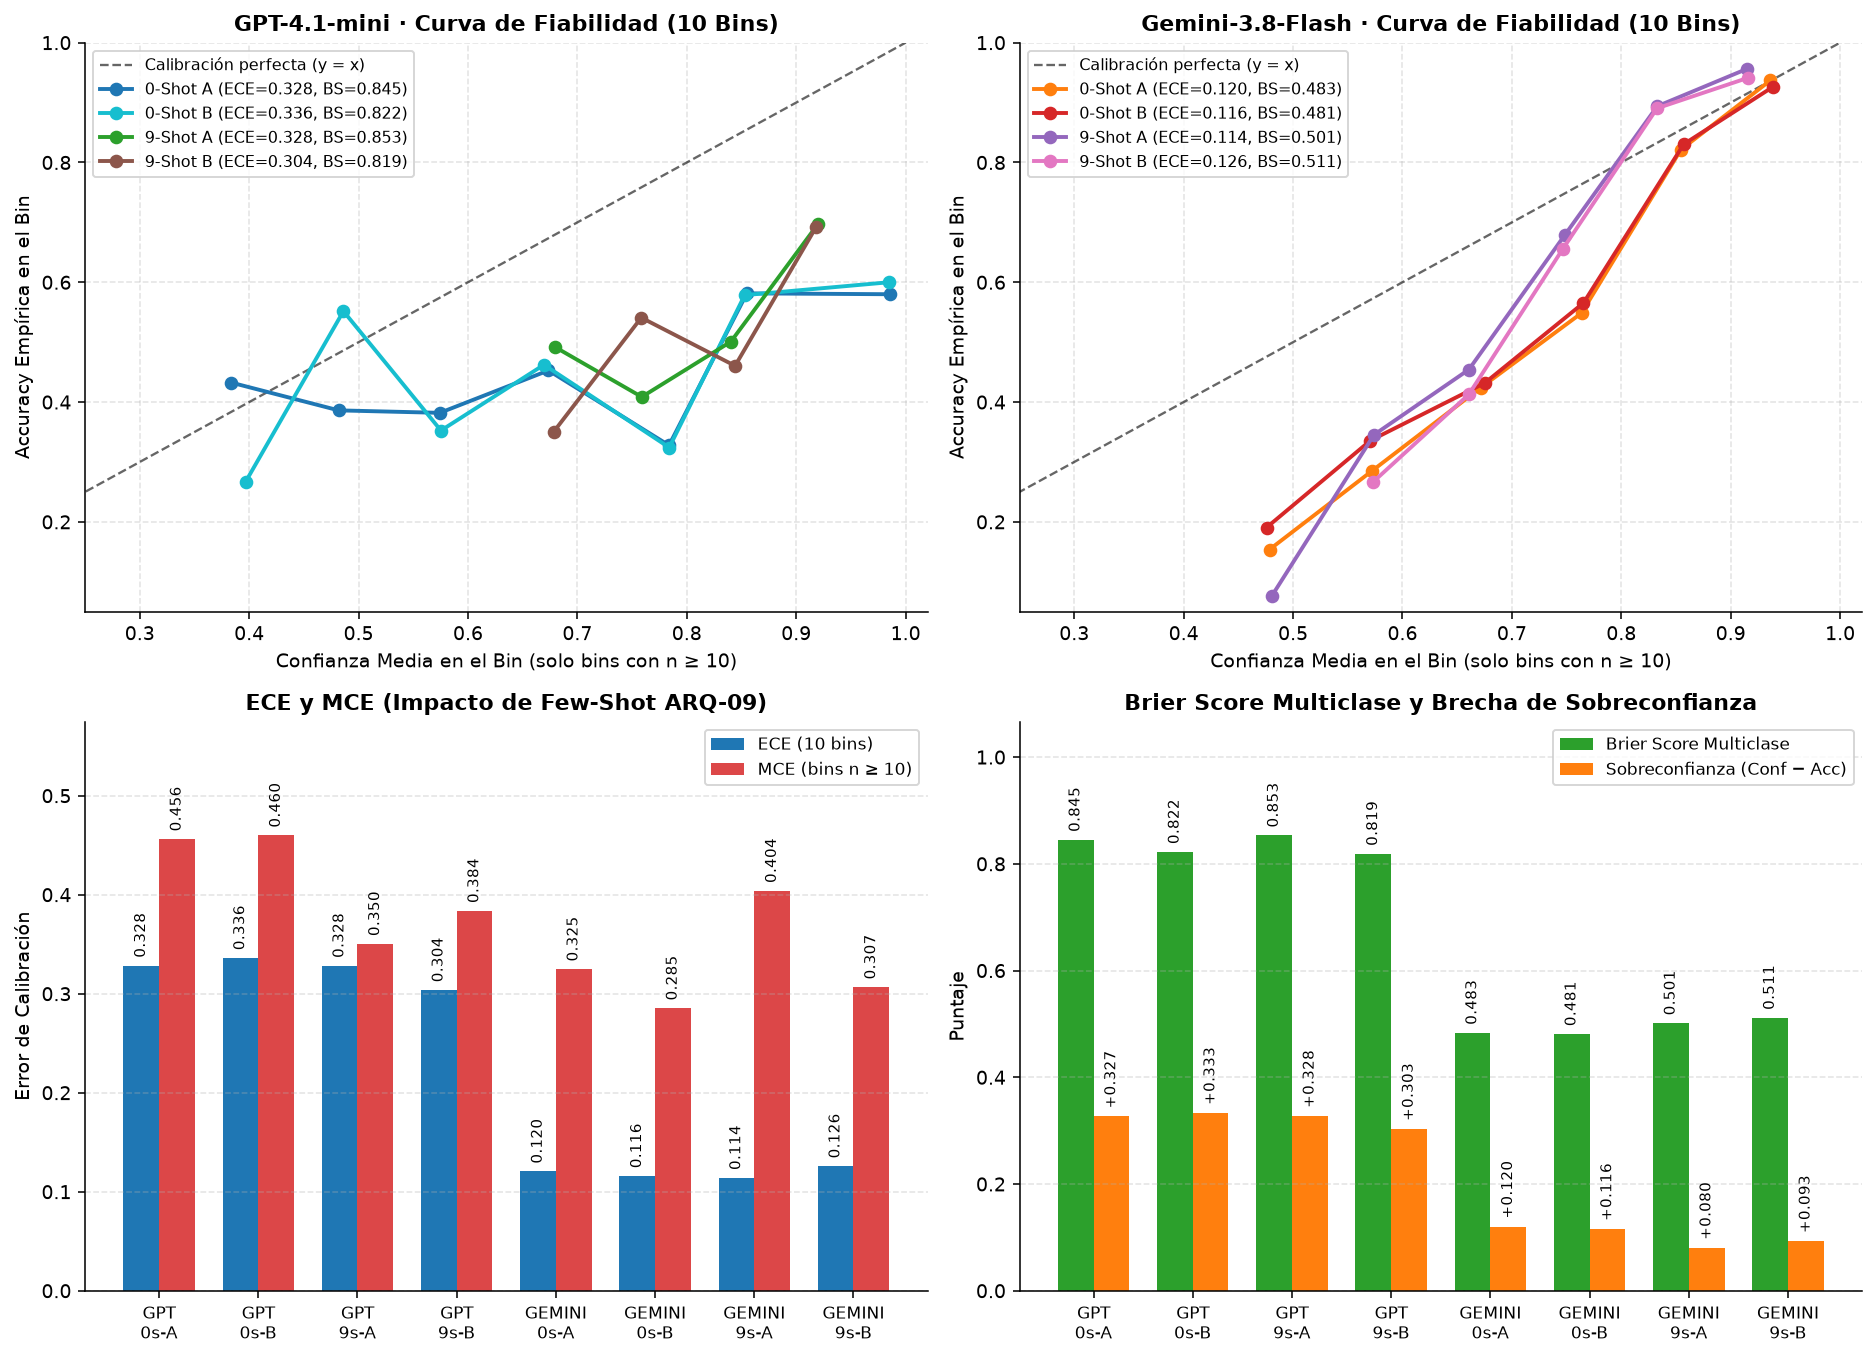

In [9]:
# Figura 5: Diagramas de Fiabilidad (Reliability Curves) + Comparativa ECE / MCE / Brier
fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.8))

# Panel 0,0 y 0,1: Reliability curves para GPT-4.1-mini y Gemini-3.8-Flash
for ax, (model_filter, title_m) in zip(
    [axes[0, 0], axes[0, 1]],
    [('gpt-4.1-mini', 'GPT-4.1-mini · Curva de Fiabilidad (10 Bins)'),
     ('gemini-3.8-flash', 'Gemini-3.8-Flash · Curva de Fiabilidad (10 Bins)')]
):
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1.2, alpha=0.6, label='Calibración perfecta (y = x)')
    for vid, label, _, _, mod, sh, cfg, _ in VARIANTS:
        if mod != model_filter:
            continue
        bs = calib_bins[vid]
        mask = bs['n'] >= 10
        row_c = df_calib[df_calib['vid'] == vid].iloc[0]
        ax.plot(bs.loc[mask, 'conf'], bs.loc[mask, 'acc'], marker='o', linewidth=2.0,
                color=COLORS[vid], label=f"{sh}-Shot {cfg} (ECE={row_c['ECE']:.3f}, BS={row_c['Brier Multiclase']:.3f})")
    ax.set_xlim(0.25, 1.02); ax.set_ylim(0.05, 1.00)
    ax.set_xlabel('Confianza Media en el Bin (solo bins con n ≥ 10)')
    ax.set_ylabel('Accuracy Empírica en el Bin')
    ax.set_title(title_m)
    ax.grid(linestyle='--', alpha=0.35)
    ax.legend(loc='upper left', fontsize=8.3, frameon=True)

# Panel 1,0: Barras ECE & MCE (bins n >= 10)
ax_ece = axes[1, 0]
x_v = np.arange(len(VARIANTS))
w = 0.36
ax_ece.bar(x_v - w/2, df_calib['ECE'], width=w, color='#1f77b4', label='ECE (10 bins)')
ax_ece.bar(x_v + w/2, df_calib['MCE (bins n>=10)'], width=w, color='#d62728', alpha=0.85, label='MCE (bins n ≥ 10)')
for idx, r in df_calib.iterrows():
    ax_ece.text(idx - w/2, r['ECE'] + 0.008, f"{r['ECE']:.3f}", ha='center', va='bottom', fontsize=7.5, rotation=90)
    ax_ece.text(idx + w/2, r['MCE (bins n>=10)'] + 0.008, f"{r['MCE (bins n>=10)']:.3f}", ha='center', va='bottom', fontsize=7.5, rotation=90)
ax_ece.set_xticks(x_v)
ax_ece.set_xticklabels([f"{r['Modelo'].split('-')[0].upper()}\n{r['Shots']}s-{r['Config']}" for _, r in df_calib.iterrows()], fontsize=8.5)
ax_ece.set_ylim(0, max(df_calib['MCE (bins n>=10)']) * 1.25)
ax_ece.set_ylabel('Error de Calibración')
ax_ece.set_title('ECE y MCE (Impacto de Few-Shot ARQ-09)')
ax_ece.grid(axis='y', linestyle='--', alpha=0.35)
ax_ece.legend(loc='upper right', fontsize=8.5, frameon=True)

# Panel 1,1: Brier Score Multiclase + Brecha de Sobreconfianza
ax_bs = axes[1, 1]
ax_bs.bar(x_v - w/2, df_calib['Brier Multiclase'], width=w, color='#2ca02c', label='Brier Score Multiclase')
ax_bs.bar(x_v + w/2, df_calib['Sobreconfianza (Conf-Acc)'], width=w, color='#ff7f0e', label='Sobreconfianza (Conf − Acc)')
for idx, r in df_calib.iterrows():
    ax_bs.text(idx - w/2, r['Brier Multiclase'] + 0.015, f"{r['Brier Multiclase']:.3f}", ha='center', va='bottom', fontsize=7.5, rotation=90)
    ax_bs.text(idx + w/2, r['Sobreconfianza (Conf-Acc)'] + 0.015, f"{r['Sobreconfianza (Conf-Acc)']:+.3f}", ha='center', va='bottom', fontsize=7.5, rotation=90)
ax_bs.set_xticks(x_v)
ax_bs.set_xticklabels([f"{r['Modelo'].split('-')[0].upper()}\n{r['Shots']}s-{r['Config']}" for _, r in df_calib.iterrows()], fontsize=8.5)
bs_min_y = min(0.0, float(df_calib['Sobreconfianza (Conf-Acc)'].min()) - 0.05)
bs_max_y = max(float(df_calib['Brier Multiclase'].max()), float(df_calib['Sobreconfianza (Conf-Acc)'].max())) * 1.25
ax_bs.set_ylim(bs_min_y, bs_max_y)
ax_bs.set_ylabel('Puntaje')
ax_bs.set_title('Brier Score Multiclase y Brecha de Sobreconfianza')
ax_bs.grid(axis='y', linestyle='--', alpha=0.35)
ax_bs.legend(loc='upper right', fontsize=8.5, frameon=True)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig05_calibracion_curvas_fiabilidad.png', bbox_inches='tight')
plt.show()


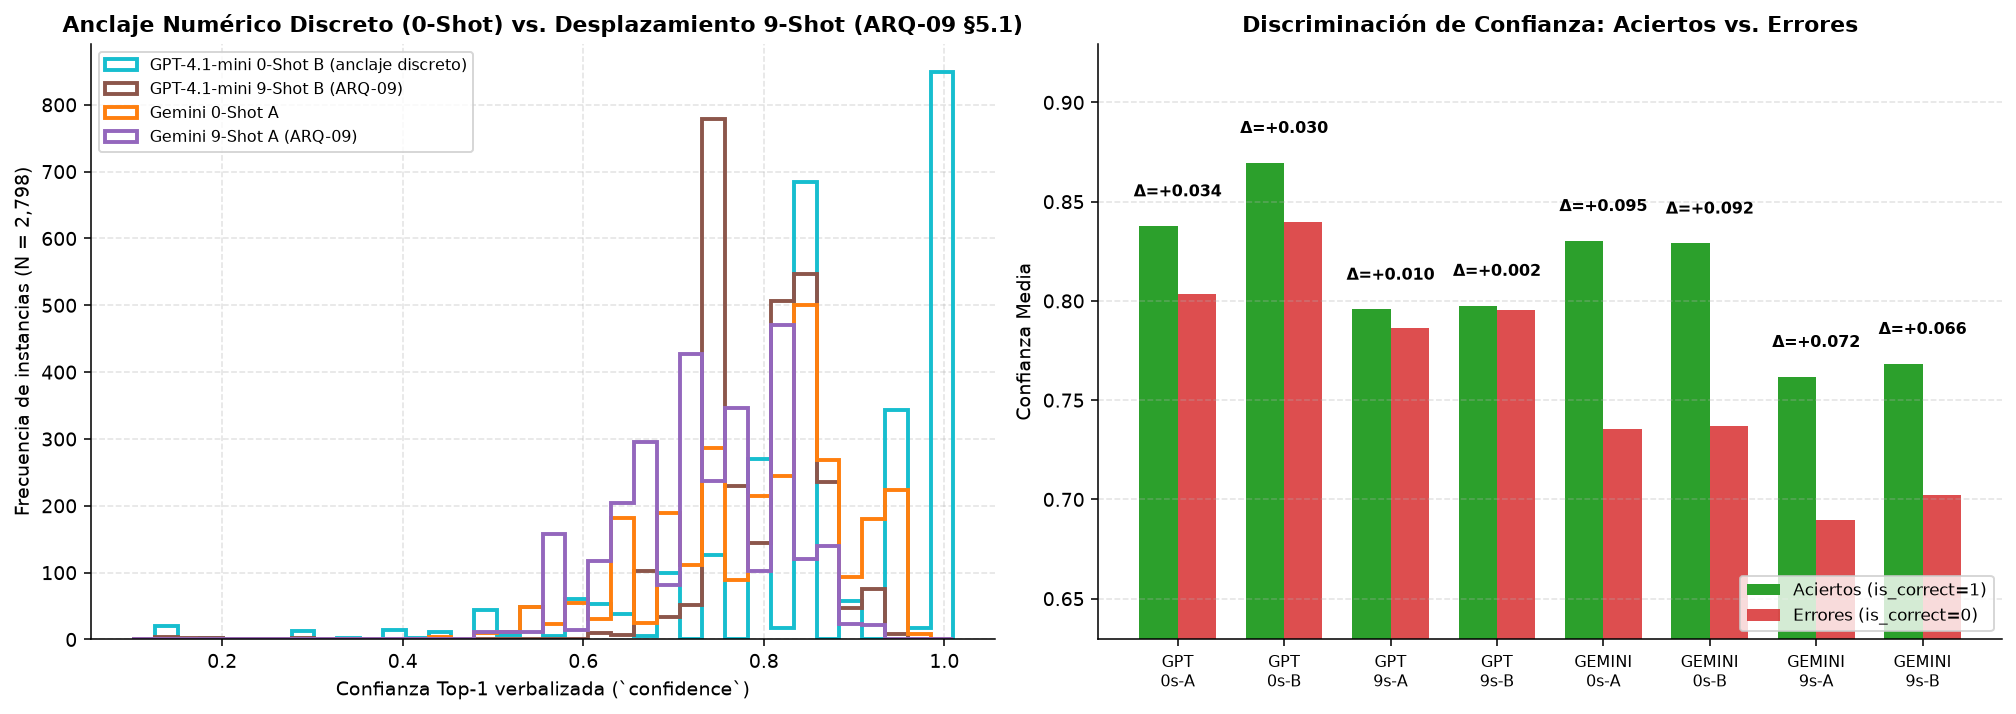

In [10]:
# Figura 6: Verificación empírica de ARQ-09 §5.1 (Anclaje discreto 0-Shot vs. Few-Shot + Confianza en Aciertos vs. Errores)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

# Panel A: Top valores discretos de confidence en GPT-4.1-mini Config B (0-Shot vs 9-Shot) y Gemini Config A
ax = axes[0]
bins_h = np.linspace(0.10, 1.01, 37)
for vid, lbl in [
    ('gpt41_zs_b',  'GPT-4.1-mini 0-Shot B (anclaje discreto)'),
    ('gpt41_fs_b',  'GPT-4.1-mini 9-Shot B (ARQ-09)'),
    ('gemini_zs_a', 'Gemini 0-Shot A'),
    ('gemini_fs_a', 'Gemini 9-Shot A (ARQ-09)'),
]:
    vals = df_all[df_all['vid'] == vid]['confidence'].to_numpy()
    ax.hist(vals, bins=bins_h, histtype='step', linewidth=2.0, density=False, color=COLORS[vid], label=lbl)
ax.set_xlabel('Confianza Top-1 verbalizada (`confidence`)')
ax.set_ylabel('Frecuencia de instancias (N = 2,798)')
ax.set_title('Anclaje Numérico Discreto (0-Shot) vs. Desplazamiento 9-Shot (ARQ-09 §5.1)')
ax.grid(linestyle='--', alpha=0.35)
ax.legend(loc='upper left', fontsize=8.2, frameon=True)

# Panel B: Confianza promedio en Aciertos vs Errores (las 8 variantes)
ax = axes[1]
x_v = np.arange(len(VARIANTS))
ok_means = [df_all[(df_all['vid'] == v[0]) & (df_all['is_correct'] == 1)]['confidence'].mean() for v in VARIANTS]
err_means = [df_all[(df_all['vid'] == v[0]) & (df_all['is_correct'] == 0)]['confidence'].mean() for v in VARIANTS]
w = 0.36
ax.bar(x_v - w/2, ok_means, width=w, color='#2ca02c', label='Aciertos (is_correct=1)')
ax.bar(x_v + w/2, err_means, width=w, color='#d62728', alpha=0.82, label='Errores (is_correct=0)')
for idx in x_v:
    diff = ok_means[idx] - err_means[idx]
    ax.text(idx, max(ok_means[idx], err_means[idx]) + 0.015, f'Δ={diff:+.3f}', ha='center', fontsize=8, fontweight='bold')
ax.set_xticks(x_v)
ax.set_xticklabels([f"{v[4].split('-')[0].upper()}\n{v[5]}s-{v[6]}" for v in VARIANTS], fontsize=8.3)
conf_min = min(ok_means + err_means)
conf_max = max(ok_means + err_means)
ax.set_ylim(max(0.0, conf_min - 0.06), min(1.02, conf_max + 0.06))
ax.set_ylabel('Confianza Media')
ax.set_title('Discriminación de Confianza: Aciertos vs. Errores')
ax.grid(axis='y', linestyle='--', alpha=0.35)
ax.legend(loc='lower right', fontsize=8.5, frameon=True)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig06_anclaje_numerico_y_confianza_acierto_error.png', bbox_inches='tight')
plt.show()


## 6. Eje 2: Latencia y Análisis de Colas (`latency_ms`)

Evaluación no paramétrica completa de `latency_ms` por modelo, configuración y modo (`p50`, `p95`, `p99`, media, desviación estándar, rango intercuartílico y análisis de *outliers* extremos $>5\text{ s}$, $>10\text{ s}$ y $>30\text{ s}$).


,Variante,Media (ms),Std (ms),Mín (ms),p25 (ms),p50 (ms),p75 (ms),p95 (ms),p99 (ms),Máx (ms),>5s (#),>10s (#),>30s (#)
0,GPT-4.1-mini · 0-Shot · A,941.7,159.9,730.2,861.7,915.9,979.8,1145.7,1445.8,3053.7,0,0,0
1,GPT-4.1-mini · 0-Shot · B,1121.0,704.8,788.7,964.1,1025.2,1128.0,1502.3,2354.6,28135.8,5,4,0
2,GPT-4.1-mini · 9-Shot · A,1024.5,193.3,791.2,923.0,986.5,1072.3,1306.2,1705.2,4902.7,0,0,0
3,GPT-4.1-mini · 9-Shot · B,1221.0,1359.7,795.1,962.9,1045.6,1186.4,1829.8,3406.0,53543.4,18,6,2
4,Gemini-3.8-Flash · 0-Shot · A,2829.6,2223.7,1263.5,2058.2,2354.0,2924.4,5269.3,10030.5,75143.5,157,29,3
5,Gemini-3.8-Flash · 0-Shot · B,2810.4,2206.1,1374.3,2041.7,2324.6,2847.8,5118.8,11271.4,39588.4,153,36,5
6,Gemini-3.8-Flash · 9-Shot · A,2567.1,1564.3,1475.6,2023.9,2292.4,2612.9,4103.2,8010.3,43311.8,78,18,2
7,Gemini-3.8-Flash · 9-Shot · B,3369.7,3811.9,1637.3,2182.5,2481.1,2938.7,7612.4,19366.4,67361.1,269,86,13



Top 10 outliers absolutos de latencia en los 22,384 llamados:


,Variante,instance_id,latency_ms,input_tokens,cached_input_tokens,thoughts_tokens,output_tokens,is_valid_format,y_true,y_pred
0,Gemini-3.8-Flash · 0-Shot · A,inst_12876,75143.496750,1290,0,129,119,True,Application,Application
1,Gemini-3.8-Flash · 9-Shot · B,inst_13253,67361.120917,7366,0,0,123,True,Background,Background
2,Gemini-3.8-Flash · 9-Shot · B,inst_08382,64272.155709,7210,0,0,121,True,Application,Application
3,Gemini-3.8-Flash · 9-Shot · B,inst_17138,57761.327792,7322,0,0,122,True,Further Reading,Further Reading
4,Gemini-3.8-Flash · 9-Shot · B,inst_08810,55512.169250,7552,0,0,123,True,Background,Basis
5,GPT-4.1-mini · 9-Shot · B,inst_08475,53543.365083,7046,6016,0,66,True,Application,Application
6,Gemini-3.8-Flash · 9-Shot · A,inst_00227,43311.754959,4875,0,0,123,True,Background,Background
7,Gemini-3.8-Flash · 0-Shot · A,inst_14031,40175.461042,1266,0,0,123,True,Background,Background
8,Gemini-3.8-Flash · 0-Shot · B,inst_16859,39588.414708,1497,0,82,124,True,Further Reading,Further Reading
9,Gemini-3.8-Flash · 0-Shot · B,inst_04795,39399.138542,1417,0,0,122,True,Background,Background


/var/folders/2r/2566d26n04v7v10k43q7jybw0000gn/T/ipykernel_42445/1607248906.py:55: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax1.boxplot(data_bp, vert=True, patch_artist=True, showfliers=False, widths=0.55)


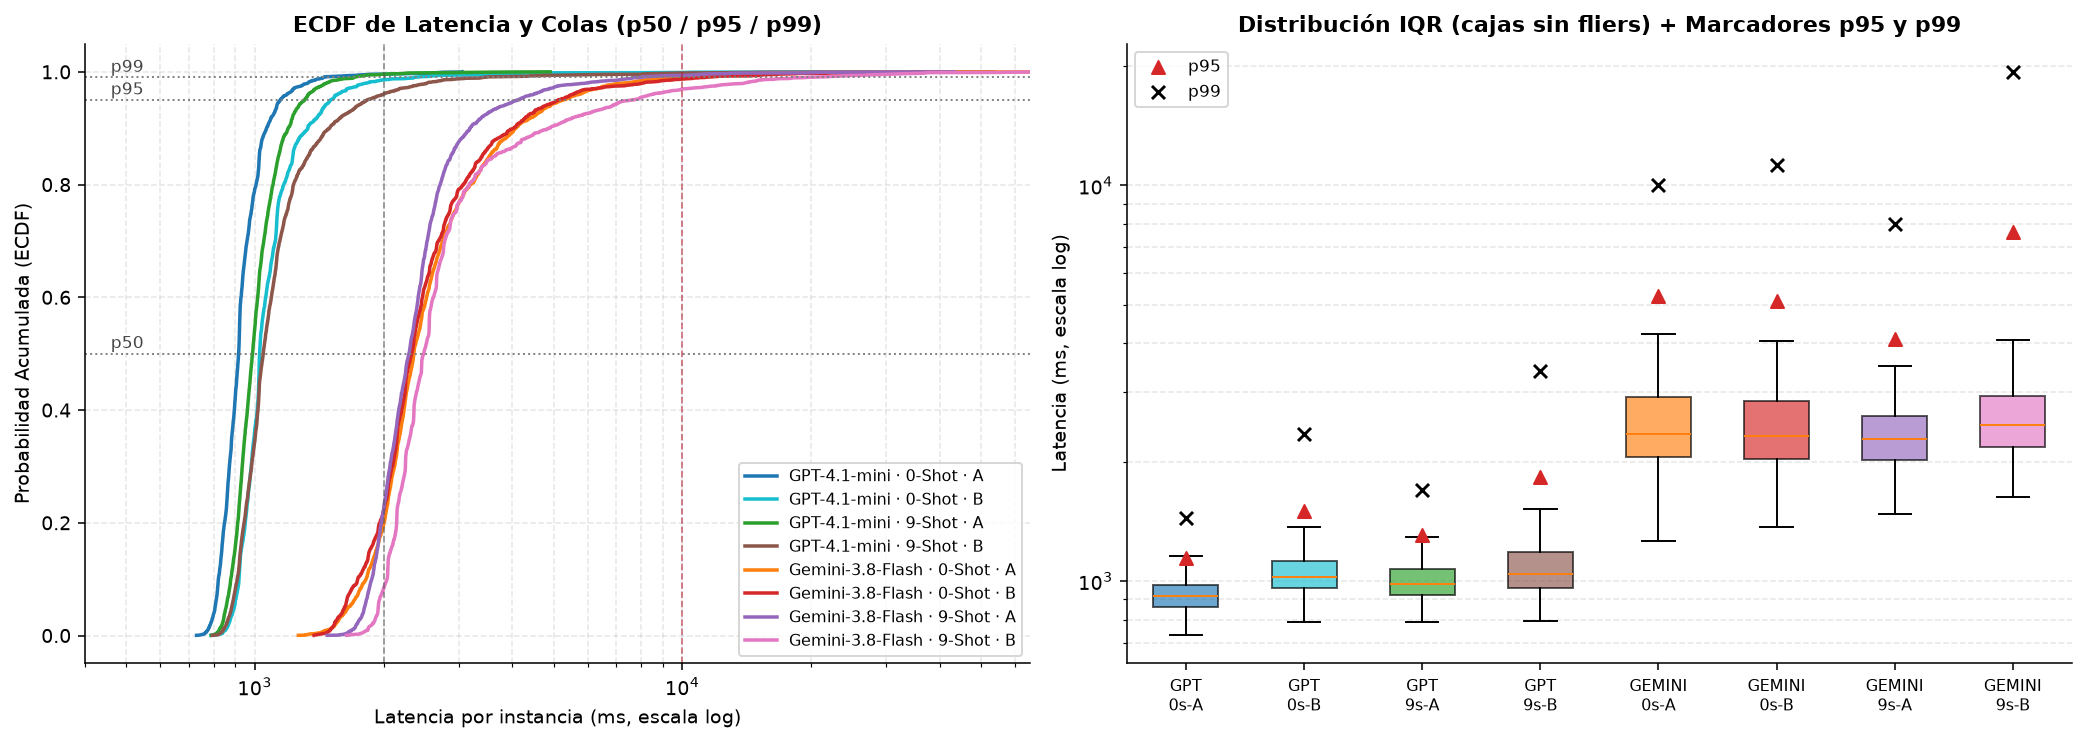

In [11]:
lat_rows = []
for vid, rinfo in runs.items():
    arr = df_all[df_all['vid'] == vid]['latency_ms'].to_numpy()
    lat_rows.append({
        'Variante': rinfo['label'],
        'Media (ms)': float(arr.mean()),
        'Std (ms)': float(arr.std(ddof=1)),
        'Mín (ms)': float(arr.min()),
        'p25 (ms)': float(np.percentile(arr, 25)),
        'p50 (ms)': float(np.percentile(arr, 50)),
        'p75 (ms)': float(np.percentile(arr, 75)),
        'p95 (ms)': float(np.percentile(arr, 95)),
        'p99 (ms)': float(np.percentile(arr, 99)),
        'Máx (ms)': float(arr.max()),
        '>5s (#)': int((arr > 5000).sum()),
        '>10s (#)': int((arr > 10000).sum()),
        '>30s (#)': int((arr > 30000).sum()),
    })

df_lat = pd.DataFrame(lat_rows)
display(df_lat.style.format({
    'Media (ms)': '{:.1f}', 'Std (ms)': '{:.1f}', 'Mín (ms)': '{:.1f}',
    'p25 (ms)': '{:.1f}', 'p50 (ms)': '{:.1f}', 'p75 (ms)': '{:.1f}',
    'p95 (ms)': '{:.1f}', 'p99 (ms)': '{:.1f}', 'Máx (ms)': '{:.1f}',
}))

print('\nTop 10 outliers absolutos de latencia en los 22,384 llamados:')
display(df_all.nlargest(10, 'latency_ms')[
    ['Variante', 'instance_id', 'latency_ms', 'input_tokens', 'cached_input_tokens', 'thoughts_tokens', 'output_tokens', 'is_valid_format', 'y_true', 'y_pred']
].reset_index(drop=True))

# Figura 7: ECDF logarítmica + Boxplot/Percentiles de latencia
fig, axes = plt.subplots(1, 2, figsize=(15.0, 5.4))

ax0 = axes[0]
for vid, label, *_ in VARIANTS:
    arr = np.sort(df_all[df_all['vid'] == vid]['latency_ms'].to_numpy())
    ecdf = np.arange(1, len(arr) + 1) / len(arr)
    ax0.plot(arr, ecdf, linewidth=1.8, color=COLORS[vid], label=label)
for ref_p, rlbl in [(0.50, 'p50'), (0.95, 'p95'), (0.99, 'p99')]:
    ax0.axhline(ref_p, color='gray', linestyle=':', linewidth=1.0)
    ax0.text(460, ref_p + 0.01, rlbl, fontsize=8.5, color='#444')
ax0.axvline(2000, color='#555', linestyle='--', linewidth=0.9, alpha=0.6)
ax0.axvline(10000, color='#b2182b', linestyle='--', linewidth=0.9, alpha=0.6)
ax0.set_xscale('log')
ax0.set_xlim(400, 65000)
ax0.set_xlabel('Latencia por instancia (ms, escala log)')
ax0.set_ylabel('Probabilidad Acumulada (ECDF)')
ax0.set_title('ECDF de Latencia y Colas (p50 / p95 / p99)')
ax0.grid(True, which='both', linestyle='--', alpha=0.3)
ax0.legend(loc='lower right', fontsize=8.0, frameon=True)

ax1 = axes[1]
data_bp = [df_all[df_all['vid'] == v[0]]['latency_ms'].to_numpy() for v in VARIANTS]
bp = ax1.boxplot(data_bp, vert=True, patch_artist=True, showfliers=False, widths=0.55)
for patch, (vid, *_) in zip(bp['boxes'], VARIANTS):
    patch.set_facecolor(COLORS[vid]); patch.set_alpha(0.65)
for idx, r in df_lat.iterrows():
    ax1.scatter([idx + 1], [r['p95 (ms)']], color='#d62728', marker='^', s=45, zorder=4, label='p95' if idx == 0 else '')
    ax1.scatter([idx + 1], [r['p99 (ms)']], color='black', marker='x', s=45, zorder=4, label='p99' if idx == 0 else '')
ax1.set_yscale('log')
ax1.set_xticks(range(1, len(VARIANTS) + 1))
ax1.set_xticklabels([f"{v[4].split('-')[0].upper()}\n{v[5]}s-{v[6]}" for v in VARIANTS], fontsize=8.3)
ax1.set_ylabel('Latencia (ms, escala log)')
ax1.set_title('Distribución IQR (cajas sin fliers) + Marcadores p95 y p99')
ax1.grid(axis='y', which='both', linestyle='--', alpha=0.3)
ax1.legend(loc='upper left', fontsize=8.5, frameon=True)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig07_latencia_ecdf_y_colas.png', bbox_inches='tight')
plt.show()


## 7. Eje 3: Tokens, Eficiencia de *Prompt Caching* y Relación con Costo / Latencia

Se comparan las distribuciones de `input_tokens`, `cached_input_tokens` y `output_tokens`, el contraste drástico entre el cacheo automático de prefijos de OpenAI (~83–84% de tokens en 9-Shot) y el cacheo implícito oportunista de Gemini (~4.3–13.4% de tokens en 9-Shot), el ahorro real en USD y el efecto empírico del caché sobre `latency_ms` dentro de las variantes 9-Shot.


,Variante,In Media,In p50,In p95,Inst Cache > 0 (%),% Tokens Cacheados,Out Media,Lat Hit p50 (ms),Lat Miss p50 (ms),Mann-Whitney p (Hit vs Miss),Costo Bruto ($),Costo Neto ($),Ahorro (%)
0,GPT-4.1-mini · 0-Shot · A,1203.4,1198,1365,1.25%,1.15%,66.1,871.0,916.4,6.842e-04,$1.6428,$1.6311,0.71%
1,GPT-4.1-mini · 0-Shot · B,1399.3,1384,1549,1.75%,1.63%,66.1,1004.4,1025.2,6.899e-02,$1.8620,$1.8429,1.03%
2,GPT-4.1-mini · 9-Shot · A,4757.4,4752,4919,99.32%,83.06%,66.2,985.9,1147.5,3.676e-05,$5.6206,$2.3037,59.01%
3,GPT-4.1-mini · 9-Shot · B,7138.3,7123,7288,99.43%,84.07%,66.1,1044.7,1220.0,1.268e-03,$8.2852,$3.2482,60.80%
4,Gemini-3.8-Flash · 0-Shot · A,1253.5,1251,1411,0.00%,0.00%,116.9,nan,2354.0,nan,$4.6320,$4.6320,0.00%
5,Gemini-3.8-Flash · 0-Shot · B,1458.1,1444,1621,0.00%,0.00%,119.1,nan,2324.6,nan,$4.9471,$4.9471,0.00%
6,Gemini-3.8-Flash · 9-Shot · A,4888.5,4886,5046,11.29%,4.33%,111.7,2517.1,2246.4,6.838e-29,$11.4325,$11.0328,3.50%
7,Gemini-3.8-Flash · 9-Shot · B,7374.1,7360,7537,22.80%,13.39%,117.8,2374.1,2540.0,9.499e-09,$16.7194,$14.8544,11.15%


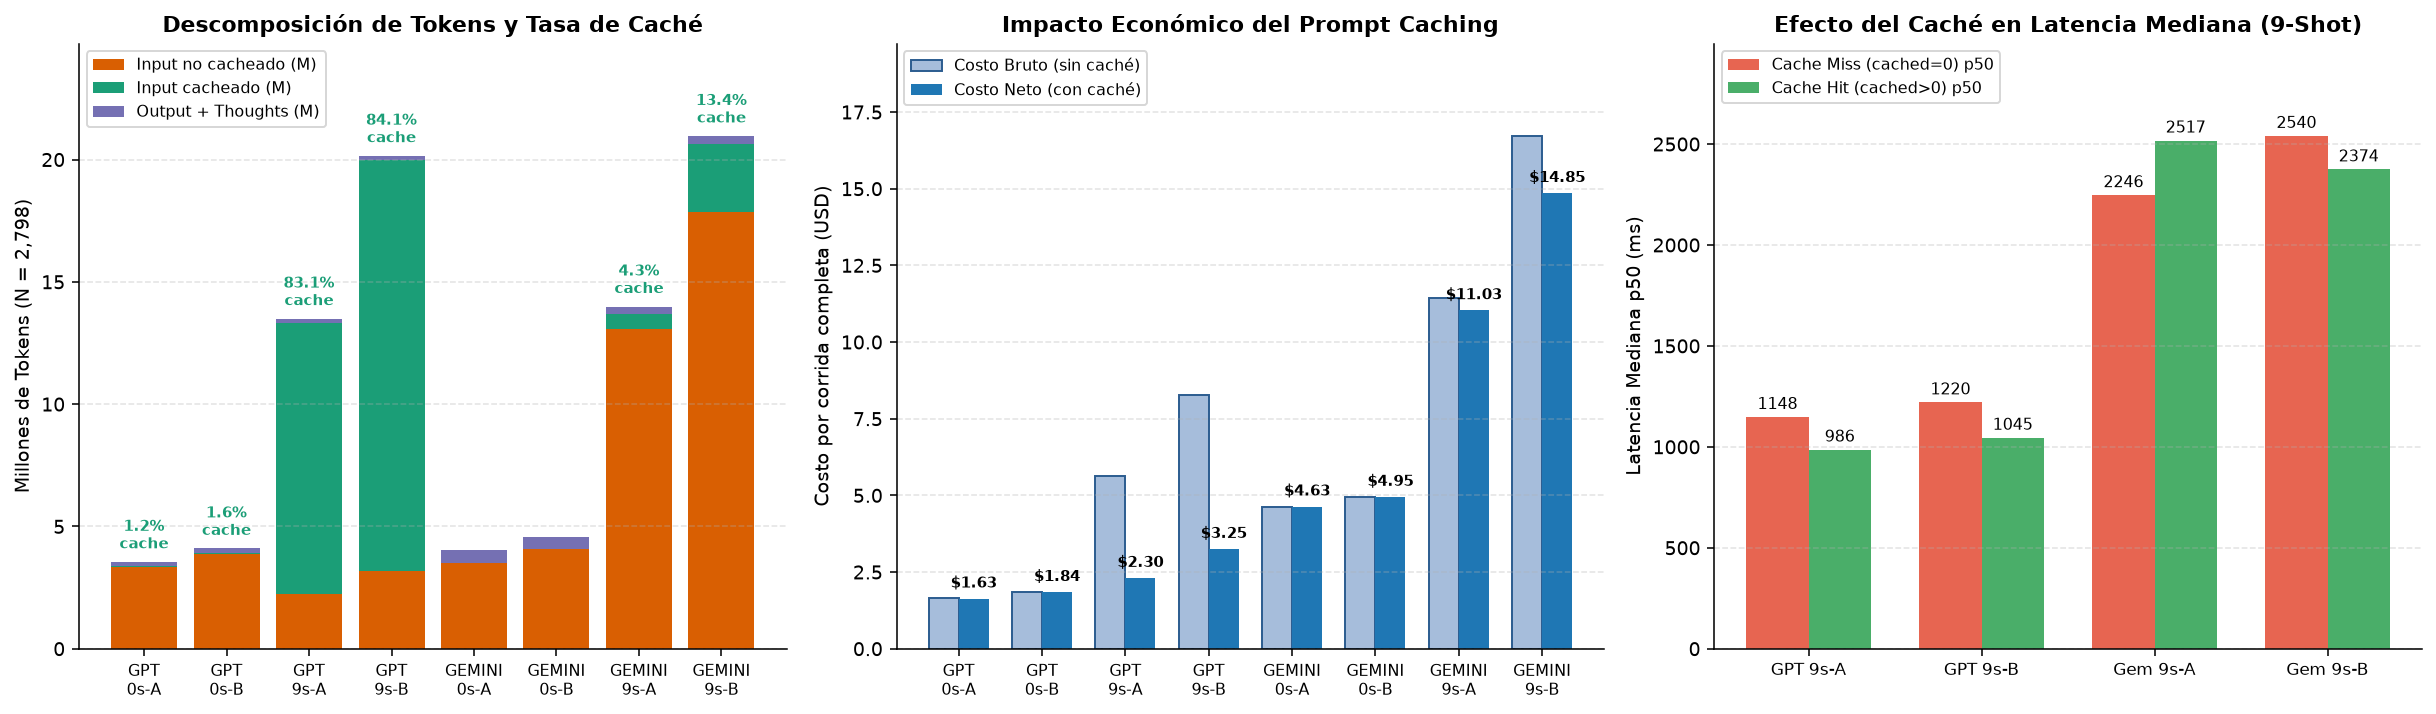

In [12]:
tok_rows = []
for vid, rinfo in runs.items():
    sub = df_all[df_all['vid'] == vid]
    hit_mask = sub['cached_input_tokens'] > 0
    hits = sub[hit_mask]
    misses = sub[~hit_mask]
    p_u = np.nan
    if len(hits) > 0 and len(misses) > 0:
        _, p_u = stats.mannwhitneyu(hits['latency_ms'], misses['latency_ms'], alternative='two-sided')
    tok_rows.append({
        'Variante': rinfo['label'],
        'In Media': sub['input_tokens'].mean(),
        'In p50': sub['input_tokens'].median(),
        'In p95': np.percentile(sub['input_tokens'], 95),
        'Inst Cache > 0 (%)': hit_mask.mean() * 100.0,
        '% Tokens Cacheados': sub['cached_input_tokens'].sum() / sub['input_tokens'].sum() * 100.0,
        'Out Media': sub['output_tokens'].mean(),
        'Lat Hit p50 (ms)': hits['latency_ms'].median() if len(hits) else np.nan,
        'Lat Miss p50 (ms)': misses['latency_ms'].median() if len(misses) else np.nan,
        'Mann-Whitney p (Hit vs Miss)': p_u,
        'Costo Bruto ($)': df_summary.loc[df_summary['vid'] == vid, 'Costo Bruto ($)'].iloc[0],
        'Costo Neto ($)': df_summary.loc[df_summary['vid'] == vid, 'Costo Neto ($)'].iloc[0],
        'Ahorro (%)': (1.0 - df_summary.loc[df_summary['vid'] == vid, 'Costo Neto ($)'].iloc[0] /
                       df_summary.loc[df_summary['vid'] == vid, 'Costo Bruto ($)'].iloc[0]) * 100.0,
    })

df_tok = pd.DataFrame(tok_rows)
display(df_tok.style.format({
    'In Media': '{:.1f}', 'In p50': '{:.0f}', 'In p95': '{:.0f}',
    'Inst Cache > 0 (%)': '{:.2f}%', '% Tokens Cacheados': '{:.2f}%', 'Out Media': '{:.1f}',
    'Lat Hit p50 (ms)': '{:.1f}', 'Lat Miss p50 (ms)': '{:.1f}',
    'Mann-Whitney p (Hit vs Miss)': '{:.3e}',
    'Costo Bruto ($)': '${:.4f}', 'Costo Neto ($)': '${:.4f}', 'Ahorro (%)': '{:.2f}%',
}))

# Figura 8: Tokens cacheados vs no cacheados + Costo Bruto/Neto + Latencia Cache Hit vs Miss
fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2))

# Panel A: Millones de tokens (Uncached vs Cached vs Output+Thoughts)
ax0 = axes[0]
x_v = np.arange(len(VARIANTS))
uncached_m = [(df_all[df_all['vid'] == v[0]]['uncached_input_tokens'].sum()) / 1e6 for v in VARIANTS]
cached_m   = [(df_all[df_all['vid'] == v[0]]['cached_input_tokens'].sum()) / 1e6 for v in VARIANTS]
out_th_m   = [((df_all[df_all['vid'] == v[0]]['output_tokens'].sum() + df_all[df_all['vid'] == v[0]]['thoughts_tokens'].sum()) / 1e6) for v in VARIANTS]
ax0.bar(x_v, uncached_m, color='#d95f02', label='Input no cacheado (M)')
ax0.bar(x_v, cached_m, bottom=uncached_m, color='#1b9e77', label='Input cacheado (M)')
ax0.bar(x_v, out_th_m, bottom=np.array(uncached_m)+np.array(cached_m), color='#7570b3', label='Output + Thoughts (M)')
for i, pct in enumerate(df_tok['% Tokens Cacheados']):
    tot = uncached_m[i] + cached_m[i] + out_th_m[i]
    if pct > 0.5:
        ax0.text(i, tot + 0.35, f'{pct:.1f}%\ncache', ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#1b9e77')
ax0.set_xticks(x_v)
ax0.set_xticklabels([f"{v[4].split('-')[0].upper()}\n{v[5]}s-{v[6]}" for v in VARIANTS], fontsize=8)
ax0.set_ylabel('Millones de Tokens (N = 2,798)')
ax0.set_title('Descomposición de Tokens y Tasa de Caché')
ax0.set_ylim(0, max(np.array(uncached_m)+np.array(cached_m)+np.array(out_th_m))*1.18)
ax0.grid(axis='y', linestyle='--', alpha=0.35)
ax0.legend(loc='upper left', fontsize=8.0, frameon=True)

# Panel B: Costo Bruto vs Neto USD
ax1 = axes[1]
w = 0.36
ax1.bar(x_v - w/2, df_tok['Costo Bruto ($)'], width=w, color='#a6bddb', edgecolor='#2b5c8f', label='Costo Bruto (sin caché)')
ax1.bar(x_v + w/2, df_tok['Costo Neto ($)'],  width=w, color='#1f77b4', label='Costo Neto (con caché)')
for idx, r in df_tok.iterrows():
    ax1.text(idx + w/2, r['Costo Neto ($)'] + 0.25, f"${r['Costo Neto ($)']:.2f}", ha='center', va='bottom', fontsize=7.5, fontweight='bold')
ax1.set_xticks(x_v)
ax1.set_xticklabels([f"{v[4].split('-')[0].upper()}\n{v[5]}s-{v[6]}" for v in VARIANTS], fontsize=8)
ax1.set_ylabel('Costo por corrida completa (USD)')
ax1.set_title('Impacto Económico del Prompt Caching')
ax1.set_ylim(0, df_tok['Costo Bruto ($)'].max() * 1.18)
ax1.grid(axis='y', linestyle='--', alpha=0.35)
ax1.legend(loc='upper left', fontsize=8.0, frameon=True)

# Panel C: Latencia Hits vs Misses en las 4 variantes 9-Shot
ax2 = axes[2]
fs_vids = ['gpt41_fs_a', 'gpt41_fs_b', 'gemini_fs_a', 'gemini_fs_b']
pos = np.arange(len(fs_vids))
hit_meds, miss_meds = [], []
for v in fs_vids:
    sub = df_all[df_all['vid'] == v]
    hit_meds.append(sub[sub['cached_input_tokens'] > 0]['latency_ms'].median())
    miss_meds.append(sub[sub['cached_input_tokens'] == 0]['latency_ms'].median())
ax2.bar(pos - w/2, miss_meds, width=w, color='#e34a33', alpha=0.85, label='Cache Miss (cached=0) p50')
ax2.bar(pos + w/2, hit_meds,  width=w, color='#31a354', alpha=0.88, label='Cache Hit (cached>0) p50')
for i in pos:
    ax2.text(i - w/2, miss_meds[i] + 40, f'{miss_meds[i]:.0f}', ha='center', fontsize=8)
    ax2.text(i + w/2, hit_meds[i]  + 40, f'{hit_meds[i]:.0f}',  ha='center', fontsize=8)
ax2.set_xticks(pos)
ax2.set_xticklabels(['GPT 9s-A', 'GPT 9s-B', 'Gem 9s-A', 'Gem 9s-B'], fontsize=8.5)
ax2.set_ylabel('Latencia Mediana p50 (ms)')
ax2.set_title('Efecto del Caché en Latencia Mediana (9-Shot)')
ax2.set_ylim(0, max(max(hit_meds), max(miss_meds)) * 1.18)
ax2.grid(axis='y', linestyle='--', alpha=0.35)
ax2.legend(loc='upper left', fontsize=8.0, frameon=True)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig08_tokens_cache_eficiencia_y_costos.png', bbox_inches='tight')
plt.show()


## 8. Eje 4: Análisis de Razonamiento (`thoughts_tokens > 0` vs. `thoughts_tokens == 0`)

Se cuantifica en qué modelos, configuraciones y modos se activa el canal de razonamiento interno (`thoughts_tokens > 0`), su supresión casi total al pasar de 0-Shot a 9-Shot en Gemini-3.8-Flash (`thinking_level="LOW"`), y se evalúa si la activación ocurre en casos más ambiguos o difíciles y si mejora o penaliza la precisión, confianza y latencia. Se reportan explícitamente los tamaños de subgrupo $n$ para evitar sobreinterpretar muestras diminutas.


In [13]:
# 1. Tabla cuantitativa de activación thoughts_tokens por variante
th_summary = []
for vid, rinfo in runs.items():
    sub = df_all[df_all['vid'] == vid]
    pos = sub[sub['thoughts_tokens'] > 0]
    n_pos = len(pos)
    th_summary.append({
        'Variante': rinfo['label'],
        'n (thoughts > 0)': n_pos,
        '% Activación': n_pos / N_TEST * 100.0,
        'n (thoughts == 0)': N_TEST - n_pos,
        'Total Thoughts': int(sub['thoughts_tokens'].sum()),
        'Media | >0': float(pos['thoughts_tokens'].mean()) if n_pos else 0.0,
        'p50 | >0': float(pos['thoughts_tokens'].median()) if n_pos else 0.0,
        'p95 | >0': float(np.percentile(pos['thoughts_tokens'], 95)) if n_pos else 0.0,
        'Máx': int(sub['thoughts_tokens'].max()),
    })
display(pd.DataFrame(th_summary).style.format({
    '% Activación': '{:.2f}%', 'Media | >0': '{:.1f}', 'p50 | >0': '{:.1f}', 'p95 | >0': '{:.1f}'
}))

# 2. Comparativa Macro-F1, Accuracy, Confianza y Latencia p50/p95: thoughts > 0 vs == 0 en las 4 variantes Gemini
th_comp_rows = []
for vid in ['gemini_zs_a', 'gemini_zs_b', 'gemini_fs_a', 'gemini_fs_b']:
    sub = df_all[df_all['vid'] == vid]
    lbl = runs[vid]['label']
    g_pos = sub[sub['thoughts_tokens'] > 0]
    g_zer = sub[sub['thoughts_tokens'] == 0]
    # Test de diferencia de proporciones de acierto (Fisher/Chi2) y latencia (Mann-Whitney)
    ct = [[int(g_pos['is_correct'].sum()), int(len(g_pos) - g_pos['is_correct'].sum())],
          [int(g_zer['is_correct'].sum()), int(len(g_zer) - g_zer['is_correct'].sum())]]
    _, p_acc = stats.fisher_exact(ct)
    _, p_lat = stats.mannwhitneyu(g_pos['latency_ms'], g_zer['latency_ms'], alternative='two-sided')
    for grp_name, g in [('thoughts > 0', g_pos), ('thoughts == 0', g_zer)]:
        # Nota: macro_f1 sobre las 9 clases; advertencia si el subgrupo tiene clases con soporte 0
        present_cls = sorted(g['y_true_idx'].unique().tolist())
        f1_all9 = f1_score(g['y_true_idx'], g['y_pred_idx'], labels=list(range(9)), average='macro', zero_division=0)
        f1_pres = f1_score(g['y_true_idx'], g['y_pred_idx'], labels=present_cls, average='macro', zero_division=0) if present_cls else 0.0
        th_comp_rows.append({
            'Variante': lbl,
            'Subgrupo': grp_name,
            'n': len(g),
            'Clases Pres.': len(present_cls),
            'Accuracy': g['is_correct'].mean(),
            'Macro-F1 (9)': f1_all9,
            'Macro-F1 (pres.)': f1_pres,
            'Conf Media': g['confidence'].mean(),
            'Input Med (tok)': g['input_tokens'].mean(),
            'Lat p50 (ms)': g['latency_ms'].median(),
            'Lat p95 (ms)': np.percentile(g['latency_ms'], 95),
            'p Accuracy (>0 vs =0)': p_acc,
            'p Latencia (>0 vs =0)': p_lat,
        })

df_th_comp = pd.DataFrame(th_comp_rows)
display(df_th_comp.style.format({
    'Accuracy': '{:.4f}', 'Macro-F1 (9)': '{:.4f}', 'Macro-F1 (pres.)': '{:.4f}',
    'Conf Media': '{:.4f}', 'Input Med (tok)': '{:.1f}',
    'Lat p50 (ms)': '{:.1f}', 'Lat p95 (ms)': '{:.1f}',
    'p Accuracy (>0 vs =0)': '{:.3e}', 'p Latencia (>0 vs =0)': '{:.3e}',
}))

# 3. Cruce por clase real, panel_agreement y longitud en Gemini Zero-Shot (donde hay suficiente n)
gem_zs = df_all[df_all['vid'].isin(['gemini_zs_a', 'gemini_zs_b'])].copy()
gem_zs['has_thoughts'] = (gem_zs['thoughts_tokens'] > 0).astype(int)

cls_th = []
for c in CANONICAL_9_CLASSES:
    sc = gem_zs[gem_zs['y_true'] == c]
    sc_pos = sc[sc['has_thoughts'] == 1]
    sc_zer = sc[sc['has_thoughts'] == 0]
    cls_th.append({
        'Clase Gold': c,
        'n total (A+B 0s)': len(sc),
        'n thoughts>0': len(sc_pos),
        '% thoughts>0': sc['has_thoughts'].mean() * 100.0,
        'Acc (th>0)': sc_pos['is_correct'].mean() if len(sc_pos) else np.nan,
        'Acc (th==0)': sc_zer['is_correct'].mean() if len(sc_zer) else np.nan,
        'Δ Acc (th>0 - th==0)': (sc_pos['is_correct'].mean() - sc_zer['is_correct'].mean()) if (len(sc_pos) and len(sc_zer)) else np.nan,
    })
df_cls_th = pd.DataFrame(cls_th).sort_values('% thoughts>0', ascending=False).reset_index(drop=True)
display(df_cls_th.style.format({
    '% thoughts>0': '{:.1f}%', 'Acc (th>0)': '{:.3f}', 'Acc (th==0)': '{:.3f}', 'Δ Acc (th>0 - th==0)': '{:+.3f}'
}))

# Cruce por consenso A2 (panel_agreement)
gem_zs['agree_bucket'] = np.where(
    gem_zs['panel_agreement'] >= 0.99, 'Unánime (1.0)',
    np.where(gem_zs['panel_agreement'] >= 0.60, 'Mayoría (0.67)', 'Empate (<0.5)')
)
agree_th = gem_zs.groupby(['agree_bucket', 'has_thoughts']).agg(
    n=('is_correct', 'size'),
    acc=('is_correct', 'mean'),
    conf=('confidence', 'mean'),
    lat_p50=('latency_ms', 'median'),
).reset_index()
display(agree_th)


,Variante,n (thoughts > 0),% Activación,n (thoughts == 0),Total Thoughts,Media | >0,p50 | >0,p95 | >0,Máx
0,GPT-4.1-mini · 0-Shot · A,0,0.00%,2798,0,0.0,0.0,0.0,0
1,GPT-4.1-mini · 0-Shot · B,0,0.00%,2798,0,0.0,0.0,0.0,0
2,GPT-4.1-mini · 9-Shot · A,0,0.00%,2798,0,0.0,0.0,0.0,0
3,GPT-4.1-mini · 9-Shot · B,0,0.00%,2798,0,0.0,0.0,0.0,0
4,Gemini-3.8-Flash · 0-Shot · A,1214,43.39%,1584,206706,170.3,123.5,435.7,1318
5,Gemini-3.8-Flash · 0-Shot · B,978,34.95%,1820,170096,173.9,126.5,421.1,1346
6,Gemini-3.8-Flash · 9-Shot · A,4,0.14%,2794,674,168.5,163.5,244.7,251
7,Gemini-3.8-Flash · 9-Shot · B,7,0.25%,2791,2277,325.3,275.0,625.0,655


,Variante,Subgrupo,n,Clases Pres.,Accuracy,Macro-F1 (9),Macro-F1 (pres.),Conf Media,Input Med (tok),Lat p50 (ms),Lat p95 (ms),p Accuracy (>0 vs =0),p Latencia (>0 vs =0)
0,Gemini-3.8-Flash · 0-Shot · A,thoughts > 0,1214,9,0.6713,0.5762,0.5762,0.7959,1248.4,2795.7,6170.6,4.137e-01,3.098e-154
1,Gemini-3.8-Flash · 0-Shot · A,thoughts == 0,1584,9,0.6862,0.6018,0.6018,0.8031,1257.4,2154.9,3700.3,4.137e-01,3.098e-154
2,Gemini-3.8-Flash · 0-Shot · B,thoughts > 0,978,9,0.6779,0.6088,0.6088,0.7960,1455.5,2832.5,6142.9,6.091e-01,6.168e-139
3,Gemini-3.8-Flash · 0-Shot · B,thoughts == 0,1820,9,0.6874,0.5942,0.5942,0.8019,1459.5,2158.6,3889.2,6.091e-01,6.168e-139
4,Gemini-3.8-Flash · 9-Shot · A,thoughts > 0,4,2,0.5000,0.0741,0.3333,0.6975,4942.8,3184.7,3769.1,6.110e-01,2.480e-02
5,Gemini-3.8-Flash · 9-Shot · A,thoughts == 0,2794,9,0.6568,0.5977,0.5977,0.7370,4888.4,2292.2,4113.5,6.110e-01,2.480e-02
6,Gemini-3.8-Flash · 9-Shot · B,thoughts > 0,7,3,0.4286,0.0833,0.2500,0.7429,7428.1,4269.8,6707.8,2.459e-01,1.212e-03
7,Gemini-3.8-Flash · 9-Shot · B,thoughts == 0,2791,9,0.6528,0.5951,0.5951,0.7453,7374.0,2478.2,7638.1,2.459e-01,1.212e-03


,Clase Gold,n total (A+B 0s),n thoughts>0,% thoughts>0,Acc (th>0),Acc (th==0),Δ Acc (th>0 - th==0)
0,Gap,146,64,43.8%,0.531,0.500,+0.031
1,Originator,210,90,42.9%,0.578,0.517,+0.061
2,Improvement,136,57,41.9%,0.596,0.570,+0.027
3,Basis,180,74,41.1%,0.865,0.858,+0.006
4,Application,1274,518,40.7%,0.805,0.798,+0.007
5,Evidence,200,78,39.0%,0.397,0.533,-0.135
6,Background,2400,935,39.0%,0.553,0.578,-0.025
7,Further Reading,454,166,36.6%,0.952,0.938,+0.014
8,Comparison,596,210,35.2%,0.814,0.813,+0.001


,agree_bucket,has_thoughts,n,acc,conf,lat_p50
0,Empate (<0.5),0,640,0.684375,0.800178,2151.793250
1,Empate (<0.5),1,424,0.648585,0.800271,2870.106791
2,Mayoría (0.67),0,1623,0.677141,0.791718,2169.388208
3,Mayoría (0.67),1,1027,0.646543,0.782818,2867.579250
4,Unánime (1.0),0,1141,0.702016,0.819091,2153.015500
5,Unánime (1.0),1,741,0.727395,0.811703,2689.740708


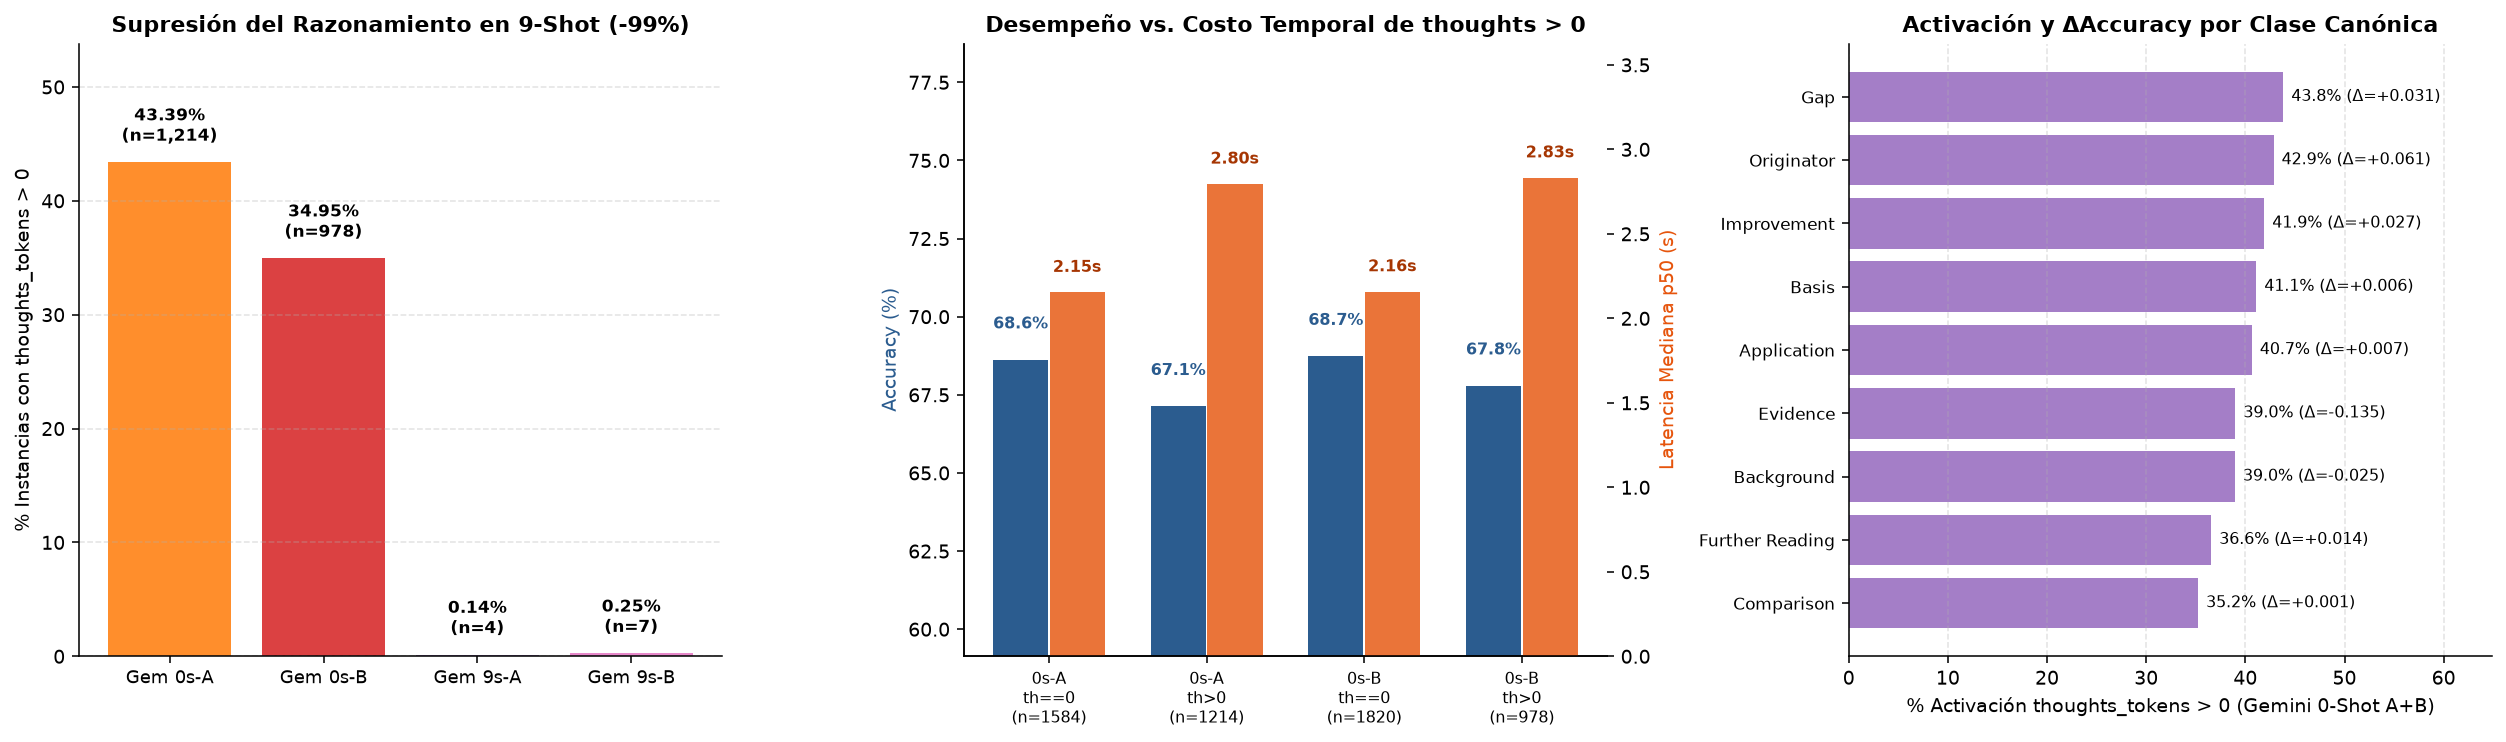

In [14]:
# Figura 9: Análisis integral de thoughts_tokens
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.4))

# Panel A: Tasa de activación thoughts > 0 por variante Gemini y distribución condicional en 0-Shot
ax0 = axes[0]
gem_vids = ['gemini_zs_a', 'gemini_zs_b', 'gemini_fs_a', 'gemini_fs_b']
act_pcts = [df_all[df_all['vid'] == v]['thoughts_tokens'].gt(0).mean() * 100.0 for v in gem_vids]
act_ns   = [int(df_all[df_all['vid'] == v]['thoughts_tokens'].gt(0).sum()) for v in gem_vids]
bars = ax0.bar(range(len(gem_vids)), act_pcts, color=[COLORS[v] for v in gem_vids], alpha=0.88)
for i, (pct, n_act) in enumerate(zip(act_pcts, act_ns)):
    ax0.text(i, pct + 1.4, f'{pct:.2f}%\n(n={n_act:,})', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
ax0.set_xticks(range(len(gem_vids)))
ax0.set_xticklabels(['Gem 0s-A', 'Gem 0s-B', 'Gem 9s-A', 'Gem 9s-B'], fontsize=9)
ax0.set_ylabel('% Instancias con thoughts_tokens > 0')
ax0.set_ylim(0, max(act_pcts) * 1.24)
ax0.set_title('Supresión del Razonamiento en 9-Shot (-99%)')
ax0.grid(axis='y', linestyle='--', alpha=0.35)

# Panel B: Accuracy y Latencia p50 en Gemini 0-Shot A y B (thoughts > 0 vs == 0)
ax1 = axes[1]
sub_pairs = [
    ('0s-A\nth==0', 'gemini_zs_a', 0),
    ('0s-A\nth>0',  'gemini_zs_a', 1),
    ('0s-B\nth==0', 'gemini_zs_b', 0),
    ('0s-B\nth>0',  'gemini_zs_b', 1),
]
accs_p, lats_p, ns_p = [], [], []
for _, v, flag in sub_pairs:
    s = df_all[(df_all['vid'] == v) & ((df_all['thoughts_tokens'] > 0).astype(int) == flag)]
    accs_p.append(s['is_correct'].mean() * 100.0)
    lats_p.append(s['latency_ms'].median() / 1000.0)
    ns_p.append(len(s))

xp = np.arange(len(sub_pairs))
b1 = ax1.bar(xp - 0.18, accs_p, width=0.35, color='#2b5c8f', label='Accuracy (%)')
ax1_r = ax1.twinx()
b2 = ax1_r.bar(xp + 0.18, lats_p, width=0.35, color='#e6550d', alpha=0.82, label='Latencia p50 (s)')
for i in xp:
    ax1.text(i - 0.18, accs_p[i] + 1.0, f'{accs_p[i]:.1f}%', ha='center', fontsize=8, color='#2b5c8f', fontweight='bold')
    ax1_r.text(i + 0.18, lats_p[i] + 0.12, f'{lats_p[i]:.2f}s', ha='center', fontsize=8, color='#a63603', fontweight='bold')
ax1.set_xticks(xp)
ax1.set_xticklabels([f'{lbl}\n(n={n})' for (lbl, _, _), n in zip(sub_pairs, ns_p)], fontsize=8.3)
ax1.set_ylabel('Accuracy (%)', color='#2b5c8f')
ax1_r.set_ylabel('Latencia Mediana p50 (s)', color='#e6550d')
ax1.set_ylim(max(0.0, min(accs_p) - 8.0), min(100.0, max(accs_p) + 10.0))
ax1_r.set_ylim(0.0, max(lats_p) * 1.28)
ax1.set_title('Desempeño vs. Costo Temporal de thoughts > 0')
ax1_r.spines['top'].set_visible(False)

# Panel C: Tasa de activación y diferencia Accuracy por clase real (Gemini 0-Shot A+B)
ax2 = axes[2]
yc = np.arange(len(df_cls_th))
ax2.barh(yc, df_cls_th['% thoughts>0'], color='#9467bd', alpha=0.85)
for i, r in df_cls_th.iterrows():
    d_str = f"{r['Δ Acc (th>0 - th==0)']:+.3f}" if pd.notna(r['Δ Acc (th>0 - th==0)']) else 'n/a'
    ax2.text(r['% thoughts>0'] + 0.8, i, f"{r['% thoughts>0']:.1f}% (Δ={d_str})",
             va='center', fontsize=8)
ax2.set_yticks(yc)
ax2.set_yticklabels(df_cls_th['Clase Gold'], fontsize=8.8)
ax2.invert_yaxis()
ax2.set_xlim(0, max(df_cls_th['% thoughts>0']) * 1.48)
ax2.set_xlabel('% Activación thoughts_tokens > 0 (Gemini 0-Shot A+B)')
ax2.set_title('Activación y ΔAccuracy por Clase Canónica')
ax2.grid(axis='x', linestyle='--', alpha=0.35)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig09_razonamiento_thoughts_subgrupos.png', bbox_inches='tight')
plt.show()


## 9. Eje 5: Análisis de Correlación Multivariada (Spearman $\rho$ y Pearson $r$)

Dado que las variables de caché, razonamiento y latencia presentan comportamientos estructuralmente distintos por régimen (`0-Shot` vs `9-Shot`, OpenAI vs Gemini), calcular correlaciones únicamente sobre la mezcla heterogénea induciría falacias de Simpson. Por ello calculamos **Spearman $\rho$** y **Pearson $r$** (con *p-values* exactos) tanto en los regímenes clave por separado como en el consolidado, enfocándonos en `input_tokens`, `cached_input_tokens`, `output_tokens`, `thoughts_tokens`, `latency_ms`, `confidence` y `is_correct`.


In [15]:
CORR_VARS = ['input_tokens', 'cached_input_tokens', 'output_tokens', 'thoughts_tokens', 'latency_ms', 'confidence', 'is_correct']
CORR_SHORT = ['in_tok', 'cache_tok', 'out_tok', 'think_tok', 'latency_ms', 'confidence', 'is_correct']

def compute_corr_pair(df_sub, vars_list):
    k = len(vars_list)
    rho_m = np.eye(k)
    r_m = np.eye(k)
    p_rho_m = np.zeros((k, k))
    p_r_m = np.zeros((k, k))
    for i in range(k):
        for j in range(k):
            if i == j:
                continue
            x = df_sub[vars_list[i]].to_numpy(dtype=float)
            y = df_sub[vars_list[j]].to_numpy(dtype=float)
            if np.std(x) == 0 or np.std(y) == 0:
                rho_m[i, j] = np.nan; r_m[i, j] = np.nan
                p_rho_m[i, j] = np.nan; p_r_m[i, j] = np.nan
            else:
                rho, prho = stats.spearmanr(x, y)
                r, pr = stats.pearsonr(x, y)
                rho_m[i, j] = rho; p_rho_m[i, j] = prho
                r_m[i, j] = r; p_r_m[i, j] = pr
    return (
        pd.DataFrame(rho_m, index=CORR_SHORT, columns=CORR_SHORT),
        pd.DataFrame(r_m, index=CORR_SHORT, columns=CORR_SHORT),
        pd.DataFrame(p_rho_m, index=CORR_SHORT, columns=CORR_SHORT),
        pd.DataFrame(p_r_m, index=CORR_SHORT, columns=CORR_SHORT),
    )

cohorts = [
    ('Global A5 (N=22,384)', df_all),
    ('Gemini 0-Shot A+B (n=5,596, thoughts activos)', df_all[df_all['vid'].isin(['gemini_zs_a', 'gemini_zs_b'])]),
    ('Gemini 9-Shot A+B (n=5,596, caché oportunista)', df_all[df_all['vid'].isin(['gemini_fs_a', 'gemini_fs_b'])]),
    ('GPT-4.1-mini 9-Shot A+B (n=5,596, caché 84%)', df_all[df_all['vid'].isin(['gpt41_fs_a', 'gpt41_fs_b'])]),
]

corr_results = {}
for cname, df_c in cohorts:
    rho_df, r_df, prho_df, pr_df = compute_corr_pair(df_c, CORR_VARS)
    corr_results[cname] = (rho_df, r_df, prho_df, pr_df)
    print(f'\n=== Correlaciones: {cname} ===')
    print('Spearman ρ:')
    display(rho_df.style.format('{:+.3f}', na_rep='const').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1))
    print('Pearson r:')
    display(r_df.style.format('{:+.3f}', na_rep='const').background_gradient(cmap='RdBu_r', vmin=-1, vmax=1))

# Imprimir top correlaciones significativas clave con p-values exactos
print('\nCorrelaciones bivariadas clave seleccionadas (r, ρ, p-valor):')
key_pairs = [
    ('Gemini 0-Shot A+B (n=5,596, thoughts activos)', 'thoughts_tokens', 'latency_ms'),
    ('Gemini 0-Shot A+B (n=5,596, thoughts activos)', 'thoughts_tokens', 'is_correct'),
    ('Gemini 0-Shot A+B (n=5,596, thoughts activos)', 'thoughts_tokens', 'confidence'),
    ('Gemini 0-Shot A+B (n=5,596, thoughts activos)', 'thoughts_tokens', 'input_tokens'),
    ('Gemini 0-Shot A+B (n=5,596, thoughts activos)', 'confidence', 'is_correct'),
    ('GPT-4.1-mini 9-Shot A+B (n=5,596, caché 84%)', 'cached_input_tokens', 'latency_ms'),
    ('GPT-4.1-mini 9-Shot A+B (n=5,596, caché 84%)', 'input_tokens', 'latency_ms'),
    ('GPT-4.1-mini 9-Shot A+B (n=5,596, caché 84%)', 'confidence', 'is_correct'),
    ('Global A5 (N=22,384)', 'input_tokens', 'latency_ms'),
    ('Global A5 (N=22,384)', 'confidence', 'is_correct'),
]
for cname, v1, v2 in key_pairs:
    df_c = dict(cohorts)[cname]
    rho, prho = stats.spearmanr(df_c[v1], df_c[v2])
    r, pr = stats.pearsonr(df_c[v1], df_c[v2])
    print(f' • {cname[:26]:<26} | {v1} vs {v2:<18}: ρ={rho:+.4f} (p={prho:.2e}) | r={r:+.4f} (p={pr:.2e})')



=== Correlaciones: Global A5 (N=22,384) ===
Spearman ρ:


,in_tok,cache_tok,out_tok,think_tok,latency_ms,confidence,is_correct
in_tok,+1.000,+0.513,+0.211,-0.268,+0.215,-0.261,-0.000
cache_tok,+0.513,+1.000,-0.405,-0.209,-0.327,-0.047,-0.099
out_tok,+0.211,-0.405,+1.000,+0.235,+0.775,-0.290,+0.159
think_tok,-0.268,-0.209,+0.235,+1.000,+0.387,+0.011,+0.054
latency_ms,+0.215,-0.327,+0.775,+0.387,+1.000,-0.222,+0.137
confidence,-0.261,-0.047,-0.290,+0.011,-0.222,+1.000,+0.193
is_correct,-0.000,-0.099,+0.159,+0.054,+0.137,+0.193,+1.000


Pearson r:


,in_tok,cache_tok,out_tok,think_tok,latency_ms,confidence,is_correct
in_tok,+1.000,+0.631,+0.009,-0.234,+0.066,-0.203,-0.022
cache_tok,+0.631,+1.000,-0.451,-0.156,-0.189,-0.023,-0.101
out_tok,+0.009,-0.451,+1.000,+0.251,+0.404,-0.184,+0.155
think_tok,-0.234,-0.156,+0.251,+1.000,+0.256,-0.107,-0.013
latency_ms,+0.066,-0.189,+0.404,+0.256,+1.000,-0.110,+0.065
confidence,-0.203,-0.023,-0.184,-0.107,-0.110,+1.000,+0.172
is_correct,-0.022,-0.101,+0.155,-0.013,+0.065,+0.172,+1.000



=== Correlaciones: Gemini 0-Shot A+B (n=5,596, thoughts activos) ===
Spearman ρ:


,in_tok,cache_tok,out_tok,think_tok,latency_ms,confidence,is_correct
in_tok,+1.000,const,-0.007,-0.081,-0.033,+0.024,+0.018
cache_tok,const,+1.000,const,const,const,const,const
out_tok,-0.007,const,+1.000,-0.033,+0.074,-0.010,+0.055
think_tok,-0.081,const,-0.033,+1.000,+0.557,-0.121,-0.075
latency_ms,-0.033,const,+0.074,+0.557,+1.000,-0.143,-0.078
confidence,+0.024,const,-0.010,-0.121,-0.143,+1.000,+0.423
is_correct,+0.018,const,+0.055,-0.075,-0.078,+0.423,+1.000


... (7 outputs left out)

,in_tok,cache_tok,out_tok,think_tok,latency_ms,confidence,is_correct
in_tok,+1.000,+0.848,-0.044,const,+0.201,+0.018,+0.010
cache_tok,+0.848,+1.000,-0.030,const,+0.223,+0.070,+0.033
out_tok,-0.044,-0.030,+1.000,const,-0.014,-0.009,+0.043
think_tok,const,const,const,+1.000,const,const,const
latency_ms,+0.201,+0.223,-0.014,const,+1.000,+0.036,+0.022
confidence,+0.018,+0.070,-0.009,const,+0.036,+1.000,+0.048
is_correct,+0.010,+0.033,+0.043,const,+0.022,+0.048,+1.000


Pearson r:


,in_tok,cache_tok,out_tok,think_tok,latency_ms,confidence,is_correct
in_tok,+1.000,+0.925,-0.025,const,+0.102,+0.039,+0.029
cache_tok,+0.925,+1.000,-0.034,const,+0.092,+0.062,+0.031
out_tok,-0.025,-0.034,+1.000,const,-0.019,-0.054,+0.043
think_tok,const,const,const,+1.000,const,const,const
latency_ms,+0.102,+0.092,-0.019,const,+1.000,+0.031,+0.001
confidence,+0.039,+0.062,-0.054,const,+0.031,+1.000,+0.042
is_correct,+0.029,+0.031,+0.043,const,+0.001,+0.042,+1.000



Correlaciones bivariadas clave seleccionadas (r, ρ, p-valor):
 • Gemini 0-Shot A+B (n=5,596 | thoughts_tokens vs latency_ms        : ρ=+0.5567 (p=0.00e+00) | r=+0.3306 (p=8.70e-143)
 • Gemini 0-Shot A+B (n=5,596 | thoughts_tokens vs is_correct        : ρ=-0.0752 (p=1.74e-08) | r=-0.1496 (p=2.31e-29)
 • Gemini 0-Shot A+B (n=5,596 | thoughts_tokens vs confidence        : ρ=-0.1211 (p=9.74e-20) | r=-0.3031 (p=2.83e-119)
 • Gemini 0-Shot A+B (n=5,596 | thoughts_tokens vs input_tokens      : ρ=-0.0809 (p=1.35e-09) | r=-0.0485 (p=2.81e-04)
 • Gemini 0-Shot A+B (n=5,596 | confidence vs is_correct        : ρ=+0.4231 (p=7.21e-242) | r=+0.4196 (p=1.27e-237)
 • GPT-4.1-mini 9-Shot A+B (n | cached_input_tokens vs latency_ms        : ρ=+0.2231 (p=4.87e-64) | r=+0.0920 (p=5.25e-12)
 • GPT-4.1-mini 9-Shot A+B (n | input_tokens vs latency_ms        : ρ=+0.2009 (p=4.62e-52) | r=+0.1015 (p=2.72e-14)
 • GPT-4.1-mini 9-Shot A+B (n | confidence vs is_correct        : ρ=+0.0479 (p=3.39e-04) | r=+0.0418 (p=

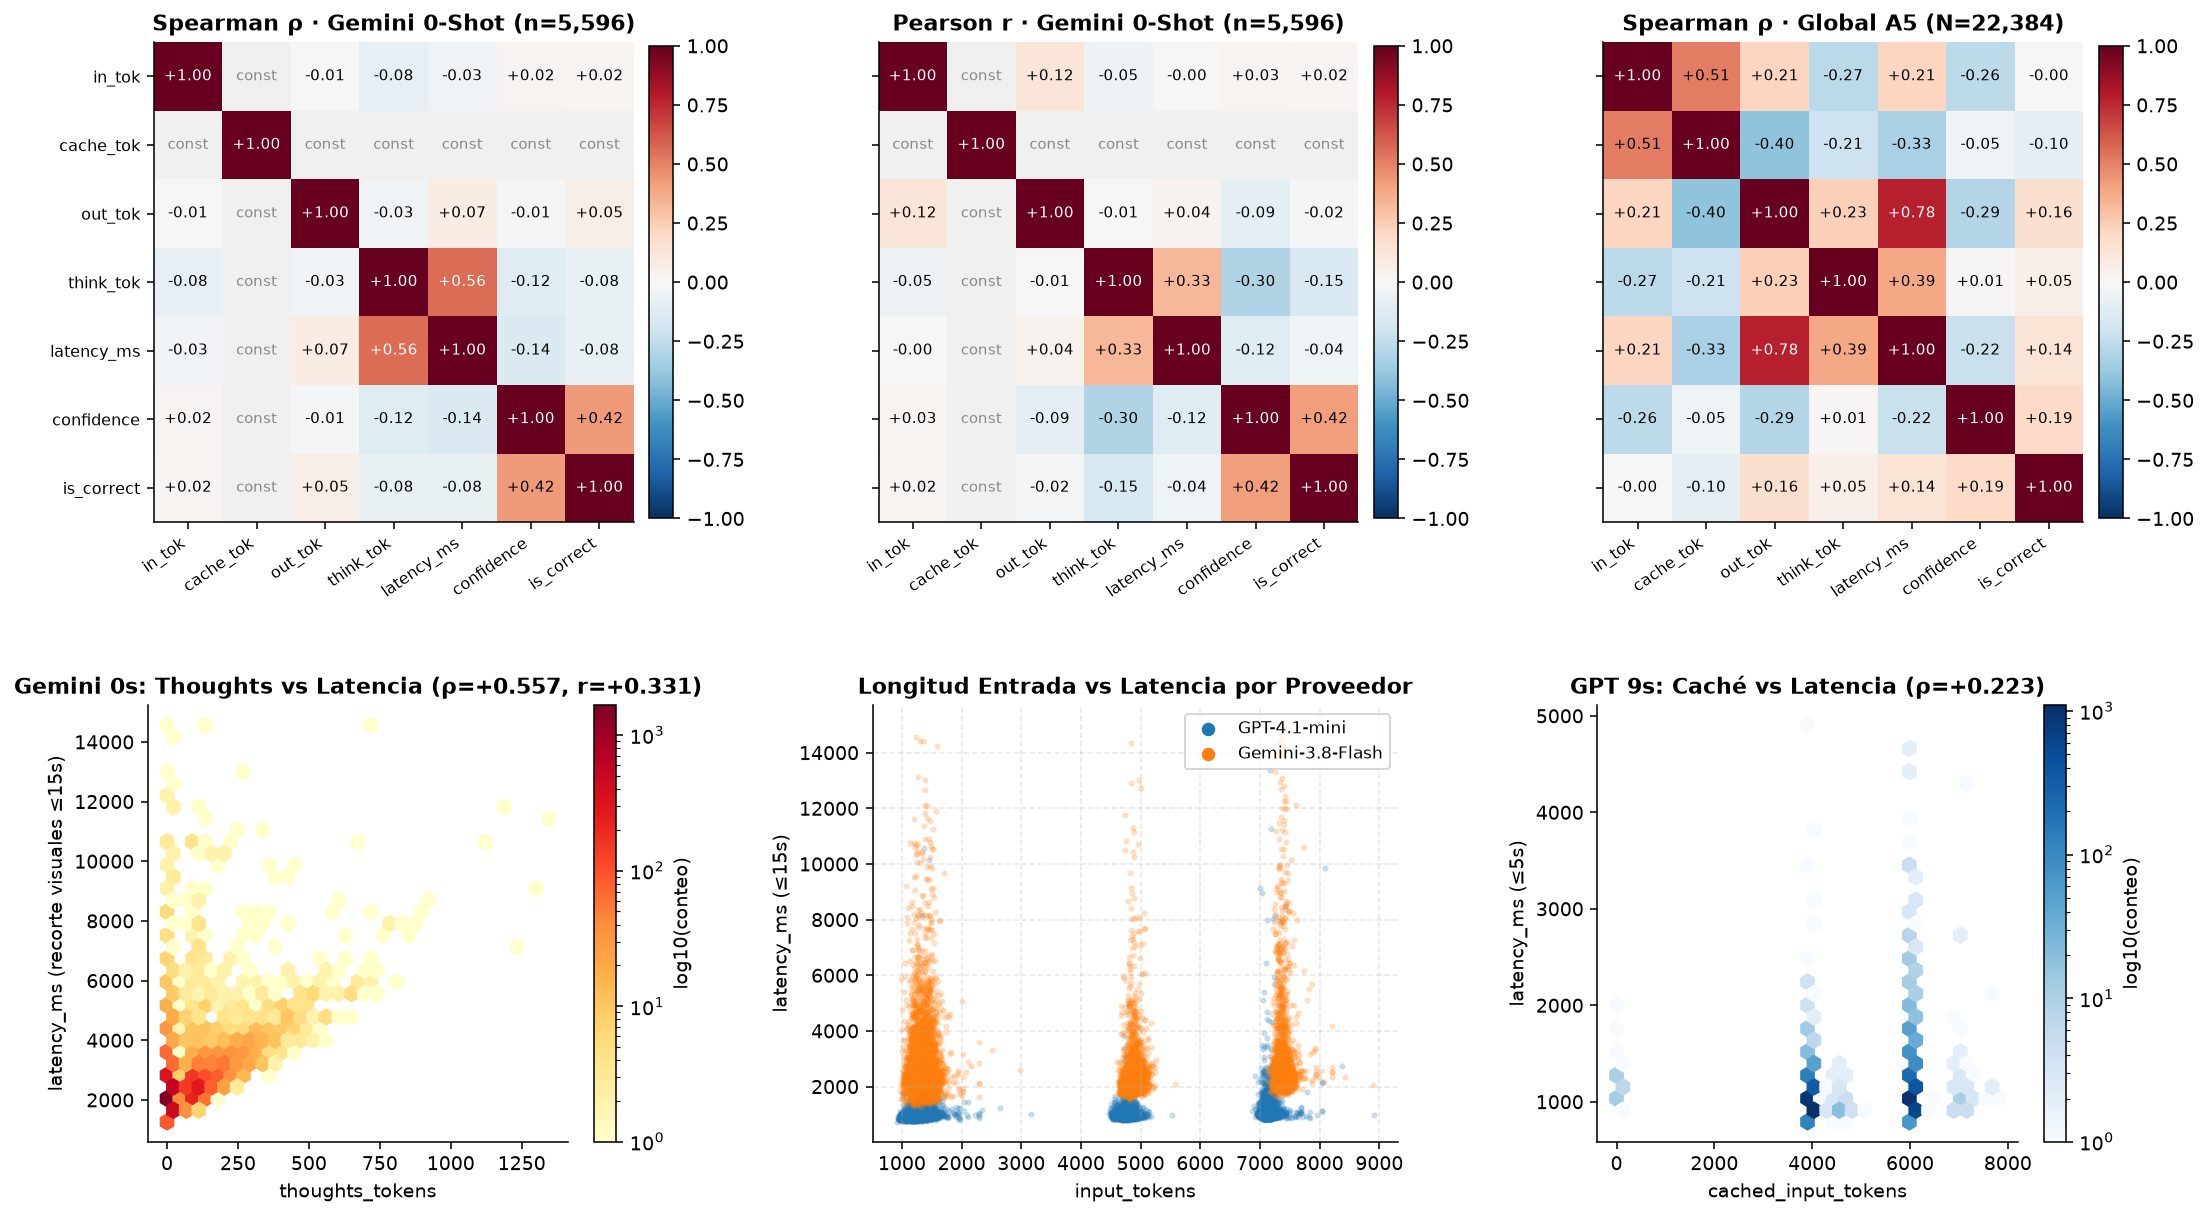

In [16]:
# Figura 10: Heatmaps Spearman vs Pearson + Hexbin/Scatter clave
fig = plt.figure(figsize=(18.2, 10.2))
gs = fig.add_gridspec(2, 3, height_ratios=[1.1, 1.0], wspace=0.38, hspace=0.40)

# Fila 1: Spearman ρ (Gemini 0s), Pearson r (Gemini 0s), Spearman ρ (Global)
panels_hm = [
    (gs[0, 0], corr_results['Gemini 0-Shot A+B (n=5,596, thoughts activos)'][0], 'Spearman ρ · Gemini 0-Shot (n=5,596)'),
    (gs[0, 1], corr_results['Gemini 0-Shot A+B (n=5,596, thoughts activos)'][1], 'Pearson r · Gemini 0-Shot (n=5,596)'),
    (gs[0, 2], corr_results['Global A5 (N=22,384)'][0],                           'Spearman ρ · Global A5 (N=22,384)'),
]
for idx_hm, (gspec, df_m, ttl) in enumerate(panels_hm):
    ax = fig.add_subplot(gspec)
    arr_m = df_m.to_numpy(dtype=float)
    masked = np.ma.masked_invalid(arr_m)
    cmap = plt.cm.RdBu_r.copy()
    cmap.set_bad(color='#f0f0f0')
    im = ax.imshow(masked, cmap=cmap, vmin=-1.0, vmax=1.0)
    ax.set_xticks(range(len(CORR_SHORT))); ax.set_yticks(range(len(CORR_SHORT)))
    ax.set_xticklabels(CORR_SHORT, rotation=35, ha='right', fontsize=8.3)
    ax.set_yticklabels(CORR_SHORT if idx_hm == 0 else [], fontsize=8.3)
    ax.set_title(ttl)
    for i in range(len(CORR_SHORT)):
        for j in range(len(CORR_SHORT)):
            v = arr_m[i, j]
            txt = 'const' if np.isnan(v) else f'{v:+.2f}'
            col = '#888' if np.isnan(v) else ('white' if abs(v) > 0.55 else 'black')
            ax.text(j, i, txt, ha='center', va='center', fontsize=7.5, color=col)
    fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)

# Fila 2: 3 scatters/hexbin clave
# (a) Gemini 0s: thoughts_tokens vs latency_ms
ax_s1 = fig.add_subplot(gs[1, 0])
df_g0 = dict(cohorts)['Gemini 0-Shot A+B (n=5,596, thoughts activos)']
sub_s1 = df_g0[df_g0['latency_ms'] <= 15000]
hb1 = ax_s1.hexbin(sub_s1['thoughts_tokens'], sub_s1['latency_ms'], gridsize=30, cmap='YlOrRd', mincnt=1, bins='log')
rho1, _ = stats.spearmanr(df_g0['thoughts_tokens'], df_g0['latency_ms'])
r1, _   = stats.pearsonr(df_g0['thoughts_tokens'], df_g0['latency_ms'])
ax_s1.set_xlabel('thoughts_tokens')
ax_s1.set_ylabel('latency_ms (recorte visuales ≤15s)')
ax_s1.set_title(f'Gemini 0s: Thoughts vs Latencia (ρ={rho1:+.3f}, r={r1:+.3f})')
fig.colorbar(hb1, ax=ax_s1, label='log10(conteo)')

# (b) Global: input_tokens vs latency_ms coloreado por familia
ax_s2 = fig.add_subplot(gs[1, 1])
for mod_n, col_m, lbl_m in [('gpt-4.1-mini', '#1f77b4', 'GPT-4.1-mini'), ('gemini-3.8-flash', '#ff7f0e', 'Gemini-3.8-Flash')]:
    sub_m = df_all[(df_all['Modelo'] == mod_n) & (df_all['latency_ms'] <= 15000)]
    ax_s2.scatter(sub_m['input_tokens'], sub_m['latency_ms'], s=5, alpha=0.18, color=col_m, label=lbl_m)
ax_s2.set_xlabel('input_tokens')
ax_s2.set_ylabel('latency_ms (≤15s)')
ax_s2.set_title('Longitud Entrada vs Latencia por Proveedor')
ax_s2.grid(linestyle='--', alpha=0.3)
leg = ax_s2.legend(loc='upper right', fontsize=8.5, frameon=True)
for lh in leg.legend_handles:
    lh.set_alpha(1.0); lh.set_sizes([35])

# (c) GPT-4.1-mini 9-Shot: cached_input_tokens vs latency_ms
ax_s3 = fig.add_subplot(gs[1, 2])
df_o9 = dict(cohorts)['GPT-4.1-mini 9-Shot A+B (n=5,596, caché 84%)']
sub_s3 = df_o9[df_o9['latency_ms'] <= 5000]
hb3 = ax_s3.hexbin(sub_s3['cached_input_tokens'], sub_s3['latency_ms'], gridsize=30, cmap='Blues', mincnt=1, bins='log')
rho3, _ = stats.spearmanr(df_o9['cached_input_tokens'], df_o9['latency_ms'])
ax_s3.set_xlabel('cached_input_tokens')
ax_s3.set_ylabel('latency_ms (≤5s)')
ax_s3.set_title(f'GPT 9s: Caché vs Latencia (ρ={rho3:+.3f})')
fig.colorbar(hb3, ax=ax_s3, label='log10(conteo)')

fig.savefig(FIG_DIR / 'fig10_correlaciones_multivariadas_y_scatter.png', bbox_inches='tight')
plt.show()


## 10. Eje 6 (Extensiones Contextualizadas): Sensibilidad por Origen A1/A2, Alineación con Panel A2 y Proyección a Escala ($N = 10{,}000$)

Conectando A5 con los antecedentes del proyecto (`ADR-13`, `ARQ-08` y `ARQ-09`):
1. Estratificamos el acierto de las 8 variantes sobre el conjunto **Gold revisado manualmente (`label_source="human_review"`)** según su origen y consenso previo A1/A2 (`prior_label_source` + `panel_agreement`: `Human Gold MultiCite`, `Panel Unánime 3/3`, `Panel Mayoría 2/3` y `Needs Review` rescatado tras desacuerdo A2).
2. Evaluamos de forma complementaria el desempeño frente al **acuerdo vs. discrepancia del Panel de Jueces A2 con la etiqueta humana** (`panel_label == y_true` vs. `panel_label != y_true`).
3. Proyectamos costo USD y tiempo de inferencia secuencial a escala operativa de **$10{,}000$ citas** con cálculo dinámico de la **frontera de Pareto no dominada**.


Estratos de origen / consenso previo A2 en test.jsonl (N=2,798):
 • Human Gold (MultiCite)      : n=563 (20.12%)
 • Panel Unánime (3/3)         : n=728 (26.02%)
 • Panel Mayoría (2/3)         : n=387 (13.83%)
 • Needs Review (desacuerdo)   : n=1,120 (40.03%)

Accuracy por estrato (Opción 1: origen / consenso previo A2):


Variante,GPT-4.1-mini · 0-Shot · A,GPT-4.1-mini · 0-Shot · B,GPT-4.1-mini · 9-Shot · A,GPT-4.1-mini · 9-Shot · B,Gemini-3.8-Flash · 0-Shot · A,Gemini-3.8-Flash · 0-Shot · B,Gemini-3.8-Flash · 9-Shot · A,Gemini-3.8-Flash · 9-Shot · B
Estrato,,,,,,,,
Human Gold (MultiCite) (n=563),0.5027,0.5187,0.4689,0.5027,0.5986,0.6075,0.5790,0.5631
Panel Unánime (3/3) (n=728),0.5701,0.5989,0.5591,0.5481,0.7253,0.7225,0.6951,0.6813
Panel Mayoría (2/3) (n=387),0.5375,0.5478,0.4832,0.5297,0.6899,0.7028,0.6770,0.6848
Needs Review (desacuerdo) (n=1120),0.4455,0.4866,0.3937,0.4482,0.6875,0.6911,0.6634,0.6670



Macro-F1 por estrato (Opción 1: origen / consenso previo A2):


Variante,GPT-4.1-mini · 0-Shot · A,GPT-4.1-mini · 0-Shot · B,GPT-4.1-mini · 9-Shot · A,GPT-4.1-mini · 9-Shot · B,Gemini-3.8-Flash · 0-Shot · A,Gemini-3.8-Flash · 0-Shot · B,Gemini-3.8-Flash · 9-Shot · A,Gemini-3.8-Flash · 9-Shot · B
Estrato,,,,,,,,
Human Gold (MultiCite) (n=563),0.4463,0.4583,0.4275,0.4326,0.4957,0.5142,0.5156,0.5005
Panel Unánime (3/3) (n=728),0.4641,0.4841,0.4671,0.4544,0.6326,0.6287,0.6182,0.6057
Panel Mayoría (2/3) (n=387),0.4837,0.4971,0.4159,0.4403,0.6096,0.6232,0.6197,0.6157
Needs Review (desacuerdo) (n=1120),0.3649,0.3887,0.3360,0.3475,0.5535,0.5634,0.5609,0.5705



Concordancia directa del Panel de Jueces A2 vs. Revisión Humana (N=2,798):
 • Panel A2 acertó vs. Humano  : n=958 (34.24%)
 • Panel A2 falló vs. Humano   : n=1,840 (65.76%)

Accuracy por concordancia Panel A2 vs. Humano (Opción 2):


Variante,GPT-4.1-mini · 0-Shot · A,GPT-4.1-mini · 0-Shot · B,GPT-4.1-mini · 9-Shot · A,GPT-4.1-mini · 9-Shot · B,Gemini-3.8-Flash · 0-Shot · A,Gemini-3.8-Flash · 0-Shot · B,Gemini-3.8-Flash · 9-Shot · A,Gemini-3.8-Flash · 9-Shot · B
Concordancia A2 vs. Humano,,,,,,,,
Panel A2 acertó vs. Humano (n=958),0.8027,0.8079,0.7359,0.7390,0.8789,0.8904,0.8852,0.8820
Panel A2 falló vs. Humano (n=1840),0.3457,0.3864,0.3228,0.3701,0.5761,0.5766,0.5375,0.5326



Macro-F1 por concordancia Panel A2 vs. Humano (Opción 2):


Variante,GPT-4.1-mini · 0-Shot · A,GPT-4.1-mini · 0-Shot · B,GPT-4.1-mini · 9-Shot · A,GPT-4.1-mini · 9-Shot · B,Gemini-3.8-Flash · 0-Shot · A,Gemini-3.8-Flash · 0-Shot · B,Gemini-3.8-Flash · 9-Shot · A,Gemini-3.8-Flash · 9-Shot · B
Concordancia A2 vs. Humano,,,,,,,,
Panel A2 acertó vs. Humano (n=958),0.7188,0.7294,0.6409,0.6649,0.7722,0.7987,0.8120,0.8080
Panel A2 falló vs. Humano (n=1840),0.2673,0.2882,0.2621,0.2676,0.4371,0.4349,0.4359,0.4307


,Variante,Macro-F1,ECE,Costo Neto / 10k ($),Costo Bruto / 10k ($),Tiempo Sec. 10k (h),Costo USD / +0.01 F1 vs base GPT-0s-A
0,GPT-4.1-mini · 0-Shot · A,0.4493,0.3284,$5.83,$5.87,2.62 h,$0.00
1,GPT-4.1-mini · 0-Shot · B,0.4664,0.3360,$6.59,$6.65,3.11 h,$0.44
2,GPT-4.1-mini · 9-Shot · A,0.4146,0.3282,$8.23,$20.09,2.85 h,— (Δ ≤ 0)
3,GPT-4.1-mini · 9-Shot · B,0.4242,0.3036,$11.61,$29.61,3.39 h,— (Δ ≤ 0)
4,Gemini-3.8-Flash · 0-Shot · A,0.5900,0.1204,$16.55,$16.55,7.86 h,$0.76
5,Gemini-3.8-Flash · 0-Shot · B,0.5996,0.1158,$17.68,$17.68,7.81 h,$0.79
6,Gemini-3.8-Flash · 9-Shot · A,0.5974,0.1139,$39.43,$40.86,7.13 h,$2.27
7,Gemini-3.8-Flash · 9-Shot · B,0.5943,0.1257,$53.09,$59.75,9.36 h,$3.26


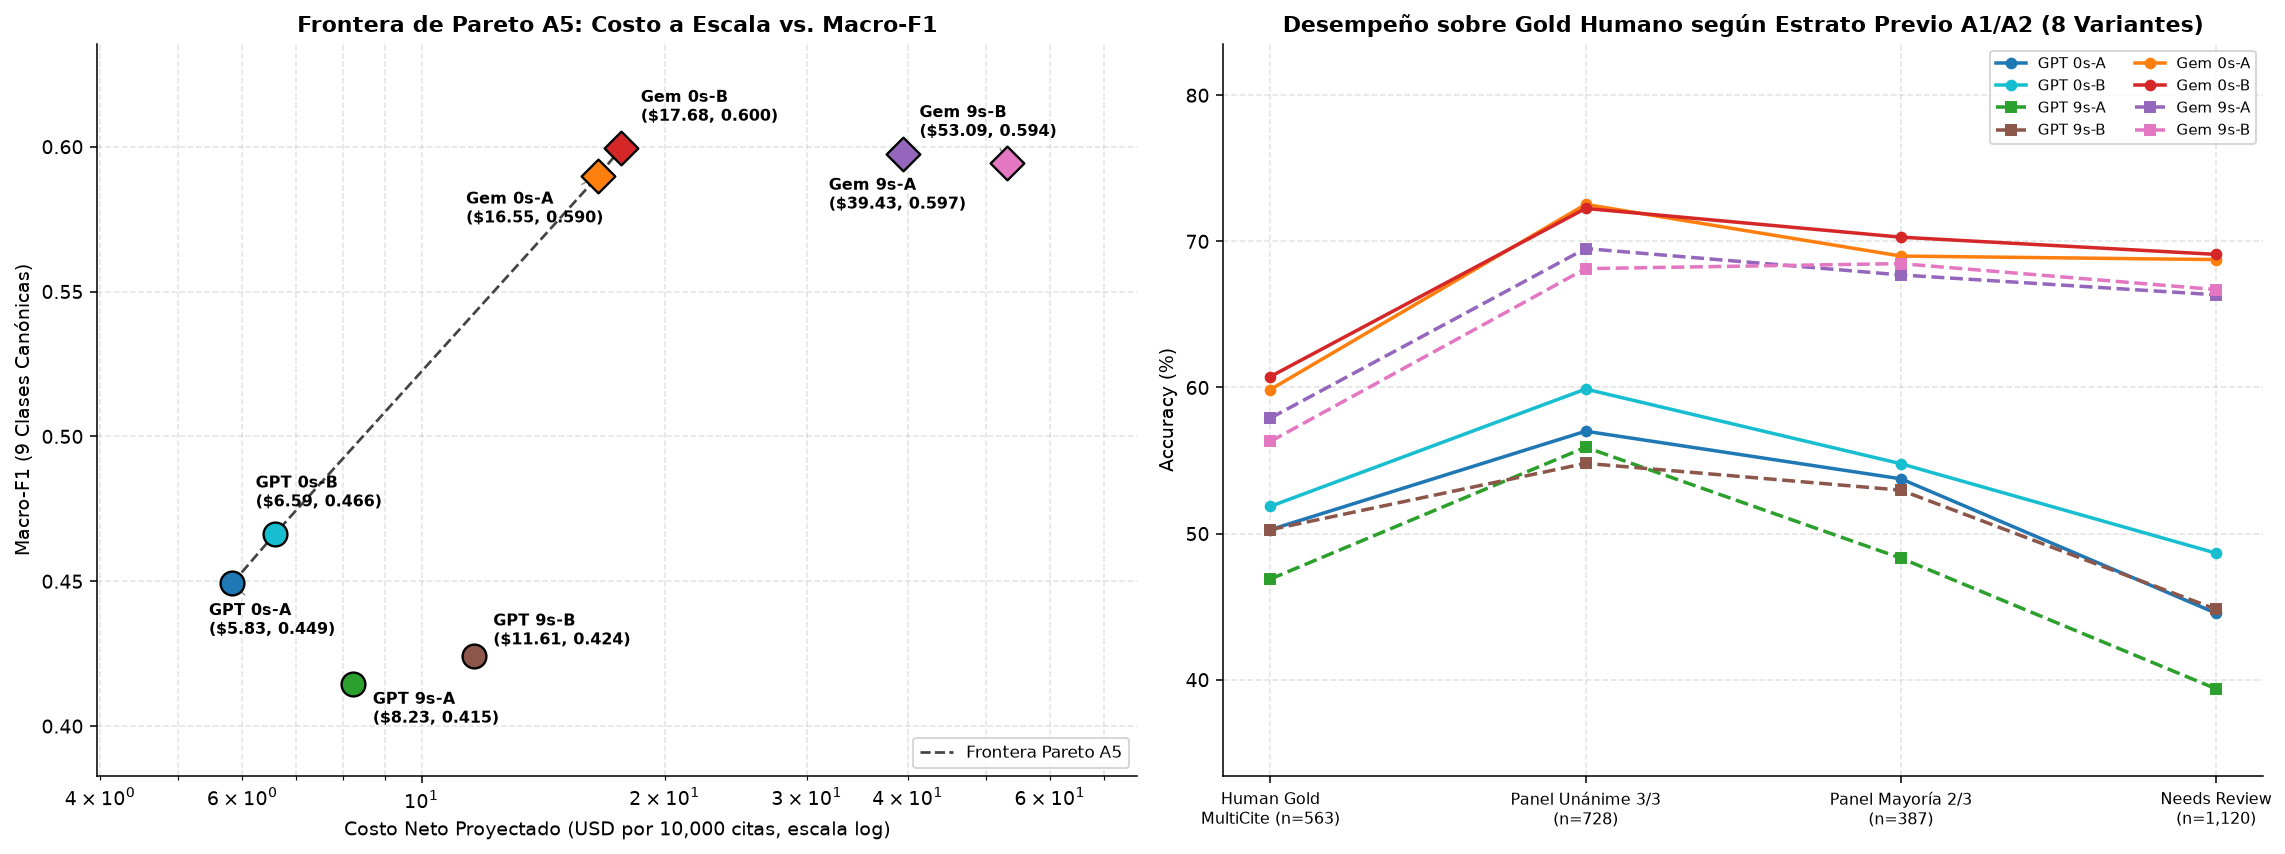

In [17]:
# 1. Sensibilidad por estrato de origen / consenso previo A2 en test.jsonl (evaluado contra Gold humano)
def agreement_stratum(row):
    ls = row['prior_label_source'] if (row['label_source'] == 'human_review' and pd.notna(row['prior_label_source'])) else row['label_source']
    pa = row['panel_agreement']
    if ls == 'human_gold':
        return 'Human Gold (MultiCite)'
    if ls == 'llm_panel' and pa is not None and pa >= 0.99:
        return 'Panel Unánime (3/3)'
    if ls == 'llm_panel':
        return 'Panel Mayoría (2/3)'
    return 'Needs Review (desacuerdo)'

strata_order = [
    'Human Gold (MultiCite)',
    'Panel Unánime (3/3)',
    'Panel Mayoría (2/3)',
    'Needs Review (desacuerdo)',
]
gold_df['stratum'] = gold_df.apply(agreement_stratum, axis=1)
df_all['stratum'] = df_all['test_idx'].map(gold_df['stratum'])
stratum_counts = gold_df['stratum'].value_counts()
print('Estratos de origen / consenso previo A2 en test.jsonl (N=2,798):')
for k in strata_order:
    v = int(stratum_counts.get(k, 0))
    print(f' • {k:<28}: n={v:,} ({v/N_TEST*100:.2f}%)')

strat_rows = []
for sname in strata_order:
    n_s = int(stratum_counts.get(sname, 0))
    if n_s == 0:
        continue
    for vid, label, *_ in VARIANTS:
        sub = df_all[(df_all['vid'] == vid) & (df_all['stratum'] == sname)]
        strat_rows.append({
            'Estrato': f'{sname} (n={n_s})',
            'stratum': sname,
            'Variante': label,
            'vid': vid,
            'Accuracy': sub['is_correct'].mean(),
            'Macro-F1': f1_score(sub['y_true_idx'], sub['y_pred_idx'], labels=list(range(9)), average='macro', zero_division=0),
        })
df_strat = pd.DataFrame(strat_rows)
idx_order_op1 = [f"{s} (n={int(stratum_counts[s])})" for s in strata_order if int(stratum_counts.get(s, 0)) > 0]
print('\nAccuracy por estrato (Opción 1: origen / consenso previo A2):')
display(df_strat.pivot(index='Estrato', columns='Variante', values='Accuracy').reindex(idx_order_op1)[[v[1] for v in VARIANTS]].style.format('{:.4f}'))
print('\nMacro-F1 por estrato (Opción 1: origen / consenso previo A2):')
display(df_strat.pivot(index='Estrato', columns='Variante', values='Macro-F1').reindex(idx_order_op1)[[v[1] for v in VARIANTS]].style.format('{:.4f}'))

# 1b. Tabla complementaria (Opción 2): Desempeño A5 según acierto/fallo del Panel A2 frente al Gold humano
gold_df['panel_match_stratum'] = np.where(
    gold_df['panel_label'] == gold_df['y_true'],
    'Panel A2 acertó vs. Humano',
    'Panel A2 falló vs. Humano',
)
df_all['panel_match_stratum'] = df_all['test_idx'].map(gold_df['panel_match_stratum'])
pm_counts = gold_df['panel_match_stratum'].value_counts()
pm_order = ['Panel A2 acertó vs. Humano', 'Panel A2 falló vs. Humano']
print('\nConcordancia directa del Panel de Jueces A2 vs. Revisión Humana (N=2,798):')
for k in pm_order:
    v = int(pm_counts.get(k, 0))
    print(f' • {k:<28}: n={v:,} ({v/N_TEST*100:.2f}%)')

pm_rows = []
for pname in pm_order:
    n_p = int(pm_counts.get(pname, 0))
    if n_p == 0:
        continue
    for vid, label, *_ in VARIANTS:
        sub = df_all[(df_all['vid'] == vid) & (df_all['panel_match_stratum'] == pname)]
        pm_rows.append({
            'Concordancia A2 vs. Humano': f'{pname} (n={n_p})',
            'Variante': label,
            'Accuracy': sub['is_correct'].mean(),
            'Macro-F1': f1_score(sub['y_true_idx'], sub['y_pred_idx'], labels=list(range(9)), average='macro', zero_division=0),
        })
df_pm = pd.DataFrame(pm_rows)
idx_order_op2 = [f"{p} (n={int(pm_counts[p])})" for p in pm_order if int(pm_counts.get(p, 0)) > 0]
print('\nAccuracy por concordancia Panel A2 vs. Humano (Opción 2):')
display(df_pm.pivot(index='Concordancia A2 vs. Humano', columns='Variante', values='Accuracy').reindex(idx_order_op2)[[v[1] for v in VARIANTS]].style.format('{:.4f}'))
print('\nMacro-F1 por concordancia Panel A2 vs. Humano (Opción 2):')
display(df_pm.pivot(index='Concordancia A2 vs. Humano', columns='Variante', values='Macro-F1').reindex(idx_order_op2)[[v[1] for v in VARIANTS]].style.format('{:.4f}'))

# 2. Tabla de proyección a escala (10,000 citas)
base_cost_10k = df_summary.loc[df_summary['vid'] == 'gpt41_zs_a', 'Costo Neto ($)'].iloc[0] / N_TEST * 10000.0
base_f1 = df_summary.loc[df_summary['vid'] == 'gpt41_zs_a', 'Macro-F1'].iloc[0]
scale_rows = []
for _, r in df_summary.iterrows():
    cost_10k_net = (r['Costo Neto ($)'] / N_TEST) * 10000.0
    cost_10k_gross = (r['Costo Bruto ($)'] / N_TEST) * 10000.0
    hours_10k_seq = (r['Lat Media (ms)'] * 10000.0) / 1000.0 / 3600.0
    delta_f1_pts = (r['Macro-F1'] - base_f1) * 100.0
    if r['vid'] == 'gpt41_zs_a':
        c_per_pt = 0.0
    elif delta_f1_pts > 0:
        c_per_pt = (cost_10k_net - base_cost_10k) / delta_f1_pts
    else:
        c_per_pt = np.nan
    scale_rows.append({
        'vid': r['vid'],
        'Variante': r['Variante'],
        'Macro-F1': r['Macro-F1'],
        'ECE': df_calib.loc[df_calib['vid'] == r['vid'], 'ECE'].iloc[0],
        'Costo Neto / 10k ($)': cost_10k_net,
        'Costo Bruto / 10k ($)': cost_10k_gross,
        'Tiempo Sec. 10k (h)': hours_10k_seq,
        'Costo USD / +0.01 F1 vs base GPT-0s-A': c_per_pt,
    })
df_scale = pd.DataFrame(scale_rows)
display(df_scale.drop(columns=['vid']).style.format({
    'Macro-F1': '{:.4f}', 'ECE': '{:.4f}',
    'Costo Neto / 10k ($)': '${:.2f}', 'Costo Bruto / 10k ($)': '${:.2f}',
    'Tiempo Sec. 10k (h)': '{:.2f} h', 'Costo USD / +0.01 F1 vs base GPT-0s-A': '${:.2f}',
}, na_rep='— (Δ ≤ 0)'))

# Figura 11: Frontera de Pareto A5 dinámica + Estratificación por consenso A2 (8 variantes)
fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.2))

# Panel A: Pareto Costo USD / 10k citas vs Macro-F1
ax0 = axes[0]
offsets = {
    'gpt41_zs_a':  (-12, -26),
    'gpt41_zs_b':  (-10, 14),
    'gpt41_fs_a':  (10, -20),
    'gpt41_fs_b':  (10, 6),
    'gemini_zs_a': (-68, -24),
    'gemini_zs_b': (10, 14),
    'gemini_fs_a': (-38, -28),
    'gemini_fs_b': (-45, 14),
}
for _, r in df_scale.iterrows():
    vid = r['vid']
    mod = df_summary.loc[df_summary['vid'] == vid, 'Modelo'].iloc[0]
    sh = df_summary.loc[df_summary['vid'] == vid, 'Shots'].iloc[0]
    cfg = df_summary.loc[df_summary['vid'] == vid, 'Config'].iloc[0]
    marker = 'o' if mod == 'gpt-4.1-mini' else 'D'
    ax0.scatter(r['Costo Neto / 10k ($)'], r['Macro-F1'], s=150, marker=marker,
                color=COLORS[vid], edgecolors='black', linewidth=1.2, zorder=4)
    lbl_pt = f"{'GPT' if 'gpt' in vid else 'Gem'} {sh}s-{cfg}\n(${r['Costo Neto / 10k ($)']:.2f}, {r['Macro-F1']:.3f})"
    dx, dy = offsets.get(vid, (8, 8))
    ax0.annotate(lbl_pt, xy=(r['Costo Neto / 10k ($)'], r['Macro-F1']), xytext=(dx, dy),
                 textcoords='offset points', fontsize=8.0, fontweight='bold',
                 arrowprops=dict(arrowstyle='-', color='#888', lw=0.7) if abs(dx) > 18 or abs(dy) > 15 else None)

# Cálculo dinámico de la frontera de Pareto no dominada (menor costo, mayor Macro-F1)
pareto_sorted = df_scale.sort_values(['Costo Neto / 10k ($)', 'Macro-F1'], ascending=[True, False])
pareto_coords = []
best_pareto_f1 = -1.0
for _, rr in pareto_sorted.iterrows():
    if rr['Macro-F1'] > best_pareto_f1:
        pareto_coords.append((rr['Costo Neto / 10k ($)'], rr['Macro-F1'], rr['vid']))
        best_pareto_f1 = rr['Macro-F1']
ax0.plot([p[0] for p in pareto_coords], [p[1] for p in pareto_coords],
         linestyle='--', color='#444', linewidth=1.4, label='Frontera Pareto A5', zorder=2)

ax0.set_xscale('log')
min_cost_x = float(df_scale['Costo Neto / 10k ($)'].min())
max_cost_x = float(df_scale['Costo Neto / 10k ($)'].max())
min_f1_y = float(df_scale['Macro-F1'].min())
max_f1_y = float(df_scale['Macro-F1'].max())
ax0.set_xlim(min_cost_x * 0.68, max_cost_x * 1.45)
ax0.set_ylim(max(0.0, min_f1_y - 0.032), min(1.0, max_f1_y + 0.036))
ax0.set_xlabel('Costo Neto Proyectado (USD por 10,000 citas, escala log)')
ax0.set_ylabel('Macro-F1 (9 Clases Canónicas)')
ax0.set_title('Frontera de Pareto A5: Costo a Escala vs. Macro-F1')
ax0.grid(True, which='both', linestyle='--', alpha=0.35)
ax0.legend(loc='lower right', fontsize=8.5, frameon=True)

# Panel B: Sensibilidad de Accuracy según Estrato de Origen / Consenso Previo A2 (8 variantes)
ax1 = axes[1]
active_strata = [s for s in strata_order if int(stratum_counts.get(s, 0)) > 0]
xs = np.arange(len(active_strata))
all_strat_vals = []
for vid, _, _, _, mod_n, sh, cfg, _ in VARIANTS:
    vals = [df_strat[(df_strat['vid'] == vid) & (df_strat['stratum'] == st)]['Accuracy'].iloc[0] * 100.0 for st in active_strata]
    all_strat_vals.extend(vals)
    short_lbl = f"{'GPT' if 'gpt' in mod_n else 'Gem'} {sh}s-{cfg}"
    ax1.plot(xs, vals, marker='o' if sh == 0 else 's', linestyle='-' if sh == 0 else '--',
             linewidth=1.8, markersize=5.0, color=COLORS[vid], label=short_lbl)
ax1.set_xticks(xs)
short_x_lbls = {
    'Human Gold (MultiCite)': f"Human Gold\nMultiCite (n={int(stratum_counts.get('Human Gold (MultiCite)', 0)):,})",
    'Panel Unánime (3/3)': f"Panel Unánime 3/3\n(n={int(stratum_counts.get('Panel Unánime (3/3)', 0)):,})",
    'Panel Mayoría (2/3)': f"Panel Mayoría 2/3\n(n={int(stratum_counts.get('Panel Mayoría (2/3)', 0)):,})",
    'Needs Review (desacuerdo)': f"Needs Review\n(n={int(stratum_counts.get('Needs Review (desacuerdo)', 0)):,})",
}
ax1.set_xticklabels([short_x_lbls[st] for st in active_strata], fontsize=8.4)
ax1.set_ylabel('Accuracy (%)')
ax1.set_ylim(max(0.0, min(all_strat_vals) - 6.0), min(100.0, max(all_strat_vals) + 11.0))
ax1.set_title('Desempeño sobre Gold Humano según Estrato Previo A1/A2 (8 Variantes)')
ax1.grid(linestyle='--', alpha=0.35)
ax1.legend(loc='upper right', fontsize=7.6, ncol=2, frameon=True)

fig.tight_layout()
fig.savefig(FIG_DIR / 'fig11_frontera_pareto_y_sensibilidad_panel.png', bbox_inches='tight')
plt.show()
